# PS4 — Statistical Machine Translation: English → German (News / Media)
**AIML ZG521 NLP Applications · Assignment 2 · Part 1 (Programming) — Member 2 track: Parts B, C and E (BLEU)**

| Section | Content |
|---|---|
| 0 | Configuration (identical to Member 1), data loading, shared `preprocess()` |
| B | IBM Model 1 with EM, written from scratch, both directions; convergence, top-5 tables, alignment heatmaps, limitations |
| C | Viterbi alignments, symmetrization, phrase extraction, phrase table, Kneser–Ney trigram LM, **own stack decoder**, beam sweep, examples → writes `outputs/smt_*` |
| E | Sentence- and corpus-level BLEU written from scratch, validated against sacreBLEU and NLTK |

No MT toolkit is used for alignment, phrase extraction, the language model or decoding. NLTK is used only to
cross-check the BLEU implementation; sacreBLEU is used as the reference metric and for validation;
sacremoses only tokenizes/detokenizes. No API keys or tokens are used anywhere.

> **Notation used throughout (noisy channel).** The task is English → German, so the *output* sentence is German.
> Following the assignment formula `score(e) = λ1·log P(f|e) + λ2·log P_LM(e)`, **e denotes the German output and
> f the English input**. The translation model in the decoder is therefore **P(English | German)** (the "inverse"
> direction from the user's point of view), and the language model is a **German** LM.

## 0. Configuration

In [1]:
import os, re, json, math, time, random, unicodedata, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sacremoses import MosesTokenizer, MosesDetokenizer
import sacrebleu, logging

logging.getLogger('sacrebleu').setLevel(logging.ERROR)   # silence 'tokenized period' hints
warnings.filterwarnings('ignore')

# Shared configuration -- identical to Member 1's notebook.
CONFIG = dict(SEED=42, MAX_LEN=30, N_TRAIN=10_000, N_TEST=500,
              EM_ITERS=10, MAX_PHRASE_LEN=4, LM_ORDER=3, BEAMS=[1, 2, 5, 10])
# Member 2 settings (Part C).
SMT = dict(SYMMETRIZATION='grow-diag-final', TABLE_LIMIT=20, DISTORTION_LIMIT=4,
           KN_DISCOUNT=0.75, N_DEV=300, OOV_PENALTY=-10.0)
C = CONFIG
SEED = C['SEED']
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd()
DATA, OUT = ROOT / 'data', ROOT / 'outputs'
FIG = OUT / 'figures'
for d in (OUT, FIG):
    d.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 120)

def read_tok(name):
    return [line.split() for line in (DATA / name).read_text(encoding='utf-8').splitlines()]

def read_lines(name):
    return (DATA / name).read_text(encoding='utf-8').splitlines()

train_en, train_de = read_tok('train.tok.en'), read_tok('train.tok.de')
test_en, test_de = read_tok('test.tok.en'), read_tok('test.tok.de')
test_raw_en, test_raw_de = read_lines('test.raw.en'), read_lines('test.raw.de')
lm_heldout = read_tok('lm_heldout.tok.de')
eval_set = pd.read_csv(DATA / 'eval_set.csv')
stress_set = pd.read_csv(DATA / 'stress_set.csv')
assert len(train_en) == len(train_de) == C['N_TRAIN'] and len(test_en) == len(test_de) == C['N_TEST']
print({k: len(v) for k, v in [('train', train_en), ('test', test_en), ('lm_heldout', lm_heldout),
                              ('eval_set', eval_set), ('stress_set', stress_set)]})

{'train': 10000, 'test': 500, 'lm_heldout': 500, 'eval_set': 15, 'stress_set': 8}


The shared tokenization function from Member 1's notebook (section A.3) is copied verbatim, so the evaluation and
stress sentences are tokenized exactly like the corpus.

In [2]:
QUOTE_MAP = str.maketrans({'„': '"', '“': '"', '”': '"', '«': '"', '»': '"',
                           '‚': "'", '‘': "'", '’': "'", '–': '-', '—': '-'})
_MOSES = {'en': MosesTokenizer(lang='en'), 'de': MosesTokenizer(lang='de')}
DETOK = MosesDetokenizer(lang='de')

def normalize(text):
    """Unicode NFC + collapsed whitespace; casing and punctuation are kept (raw text)."""
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', text)).strip()

def preprocess(text, lang):
    """normalize -> ASCII quotes/dashes -> Moses tokenization -> lowercase. Returns a list of tokens."""
    text = normalize(text).translate(QUOTE_MAP)
    return [tok.lower() for tok in _MOSES[lang].tokenize(text, escape=False)]

# Sanity check: re-tokenizing the raw test English reproduces the provided tokenized file.
same = sum(preprocess(r, 'en') == t for r, t in zip(test_raw_en, test_en))
print(f'preprocess() reproduces test.tok.en on {same}/{len(test_en)} sentences')

preprocess() reproduces test.tok.en on 500/500 sentences


## Part B — IBM Model 1 word alignment with EM (from scratch)

### B.1 Model and algorithm
IBM Model 1 (Brown et al. 1993) generates a target sentence $f = f_1 \dots f_m$ from a conditioning sentence
$e = e_0 e_1 \dots e_l$, where $e_0$ is the **NULL** word. Each $f_j$ independently picks an alignment
$a_j \in \{0,\dots,l\}$ uniformly, then is generated with probability $t(f_j \mid e_{a_j})$:

$$P(f \mid e) = \frac{\epsilon}{(l+1)^m} \prod_{j=1}^{m} \sum_{i=0}^{l} t(f_j \mid e_i)$$

**EM.** *Initialization:* $t(f\mid e)$ is uniform, $1/|V_f|$, over all co-occurring word pairs.
*E-step:* the alignment posterior factorises per position,
$P(a_j = i \mid f, e) = t(f_j\mid e_i) / \sum_{i'} t(f_j\mid e_{i'})$, and it is accumulated into expected
counts $c(f, e)$. *M-step:* $t(f\mid e) = c(f,e) / \sum_{f'} c(f', e)$.
The corpus log-likelihood $\sum_s \log P(f^{(s)} \mid e^{(s)})$ (dropping the constant $\epsilon$) never
decreases under EM, which we check after every iteration.

**Implementation.** Each of the ~3.8M possible links (sentence, $j$, $i$) is stored once as an integer index into a
flat parameter vector over the ~1.5M co-occurring $(e, f)$ pairs. Both EM steps then become three
`np.bincount` calls (sums over links grouped by target position, by pair, and by conditioning word). This is
plain NumPy arithmetic, with no MT library. The same class is trained in **both directions**, because Part C
symmetrizes the two Viterbi alignments.

In [3]:
NULL = '<NULL>'

class IBMModel1:
    """IBM Model 1, t(f | e), with a NULL token on the conditioning (e) side. Written from scratch.

    Every link (sentence s, target position j, source position i incl. NULL) is stored once as
      P[k] : index of the word pair (e_i, f_j) in the flat parameter vector `t`
      G[k] : id of the (s, j) group -- the posterior is normalised within each group
    so the E- and M-steps are vectorised with np.bincount.
    """

    def __init__(self, f_sents, e_sents):
        self.f_sents, self.e_sents = f_sents, e_sents
        self.e_vocab, self.f_vocab, self.pair_index = {NULL: 0}, {}, {}
        P, G, self.slices = [], [], []
        g = 0
        for fs, es in zip(f_sents, e_sents):
            e_ids = [0] + [self.e_vocab.setdefault(w, len(self.e_vocab)) for w in es]
            start = len(P)
            for fw in fs:
                fi = self.f_vocab.setdefault(fw, len(self.f_vocab))
                for ei in e_ids:
                    P.append(self.pair_index.setdefault((ei, fi), len(self.pair_index)))
                    G.append(g)
                g += 1
            self.slices.append((start, len(P), len(fs), len(e_ids)))
        self.P, self.G, self.n_groups = np.asarray(P), np.asarray(G), g
        pairs = np.asarray(list(self.pair_index), dtype=np.int64)
        self.pair_e, self.pair_f = pairs[:, 0], pairs[:, 1]
        self.t = np.full(len(pairs), 1.0 / len(self.f_vocab))          # uniform initialisation
        self.n_tokens = sum(len(fs) for fs in f_sents)
        self._len_term = sum(len(fs) * math.log(len(es) + 1) for fs, es in zip(f_sents, e_sents))
        self.i2f = {i: w for w, i in self.f_vocab.items()}
        self.i2e = {i: w for w, i in self.e_vocab.items()}

    def log_likelihood(self):
        """sum_s log P(f|e) = sum_{s,j} log sum_i t(f_j|e_i) - sum_s m_s log(l_s + 1)   (epsilon dropped)."""
        z = np.bincount(self.G, weights=self.t[self.P], minlength=self.n_groups)
        return float(np.log(z).sum() - self._len_term)

    def em_iteration(self):
        T = self.t[self.P]
        z = np.bincount(self.G, weights=T, minlength=self.n_groups)            # E-step: normaliser per (s, j)
        posterior = T / z[self.G]                                               #   P(a_j = i | f, e)
        counts = np.bincount(self.P, weights=posterior, minlength=len(self.t))  #   expected c(f, e)
        totals = np.bincount(self.pair_e, weights=counts, minlength=len(self.e_vocab))
        self.t = counts / totals[self.pair_e]                                   # M-step

    def train(self, iterations):
        self.history = [self.log_likelihood()]
        for _ in range(iterations):
            self.em_iteration()
            self.history.append(self.log_likelihood())
        return self.history

    # ---- inspection helpers -------------------------------------------------------------------
    def prob(self, f, e):
        k = self.pair_index.get((self.e_vocab.get(e, -1), self.f_vocab.get(f, -1)))
        return 0.0 if k is None else float(self.t[k])

    def top_translations(self, e, k=5):
        if e not in self.e_vocab:
            return []
        idx = np.flatnonzero(self.pair_e == self.e_vocab[e])
        best = idx[np.argsort(-self.t[idx])[:k]]
        return [(self.i2f[self.pair_f[b]], float(self.t[b])) for b in best]

    def posteriors(self, s):
        """(m x (l+1)) matrix of P(a_j = i | f, e) for training pair s; column 0 is NULL."""
        start, end, m, l1 = self.slices[s]
        T = self.t[self.P[start:end]].reshape(m, l1)
        return T / T.sum(1, keepdims=True)

    def posteriors_for(self, fs, es):
        """Same as `posteriors`, for an arbitrary sentence pair (unseen pairs get t = 0)."""
        T = np.array([[self.prob(f, e) for e in [NULL] + es] for f in fs]) + 1e-12
        return T / T.sum(1, keepdims=True)

    def viterbi(self, s):
        """Best alignment a_j for every target position j of pair s (0 = NULL, else 1-based source index)."""
        return self.posteriors(s).argmax(1)

### B.2 Training in both directions and convergence
* `m_de_en` learns $t(\text{de} \mid \text{en})$: English conditions, German is generated (NULL is English).
* `m_en_de` learns $t(\text{en} \mid \text{de})$: German conditions, English is generated (NULL is German).
  This is the direction of the decoder's noisy-channel model $P(f\mid e)$.

In [4]:
t0 = time.perf_counter()
m_de_en = IBMModel1(f_sents=train_de, e_sents=train_en)    # t(de | en)
m_en_de = IBMModel1(f_sents=train_en, e_sents=train_de)    # t(en | de)
build_s = time.perf_counter() - t0

t0 = time.perf_counter()
hist = {'t(de|en)': m_de_en.train(C['EM_ITERS']), 't(en|de)': m_en_de.train(C['EM_ITERS'])}
train_s = time.perf_counter() - t0
print(f'index build {build_s:.1f}s, {C["EM_ITERS"]} EM iterations x 2 directions in {train_s:.1f}s')
print(f't(de|en): {len(m_de_en.t):,} co-occurring pairs, {len(m_de_en.P):,} links')

for name, h in hist.items():
    assert all(b >= a - 1e-6 for a, b in zip(h, h[1:])), f'{name}: log-likelihood decreased'
models = {'t(de|en)': m_de_en, 't(en|de)': m_en_de}
conv = pd.DataFrame({
    **{f'LL {n}': np.round(h, 1) for n, h in hist.items()},
    **{f'per-word PPL {n}': np.round(np.exp(-np.array(h) / models[n].n_tokens), 2) for n, h in hist.items()},
}, index=pd.RangeIndex(0, C['EM_ITERS'] + 1, name='iteration'))
print('log-likelihood increases monotonically in both directions: OK')
conv

index build 1.8s, 10 EM iterations x 2 directions in 0.9s
t(de|en): 1,508,126 co-occurring pairs, 3,812,805 links
log-likelihood increases monotonically in both directions: OK


,LL t(de|en),LL t(en|de),per-word PPL t(de|en),per-word PPL t(en|de)
iteration,,,,
0,-1806173.9,-1716515.5,23197.00,15192.00
1,-854301.3,-777244.2,116.09,78.24
2,-759975.4,-688035.3,68.68,47.44
3,-720585.7,-648393.9,55.16,37.98
4,-704857.7,-632094.0,50.54,34.66
5,-697577.7,-624598.3,48.53,33.23
6,-693691.7,-620689.6,47.49,32.51
7,-691391.2,-618434.9,46.89,32.11
8,-689925.5,-617025.8,46.51,31.85


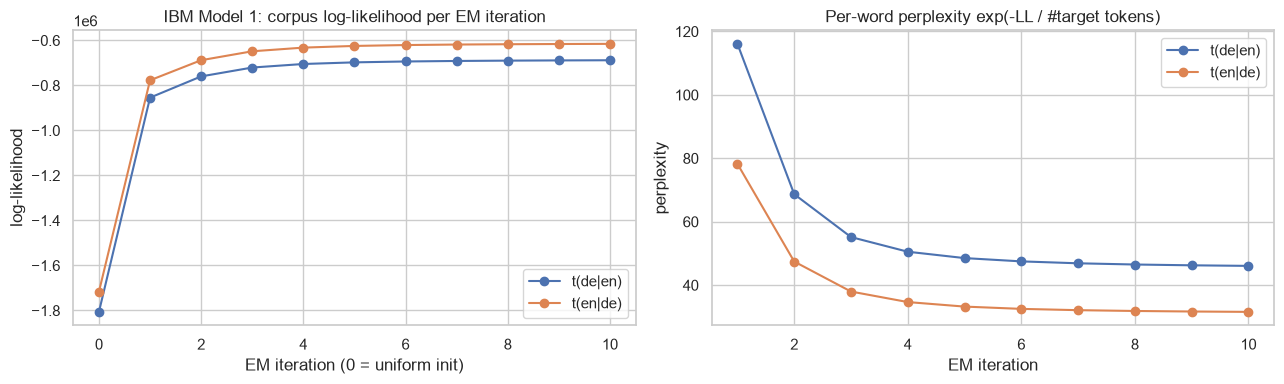

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, h in hist.items():
    ax[0].plot(range(len(h)), h, marker='o', label=name)
    ax[1].plot(range(1, len(h)), np.exp(-np.array(h[1:]) / models[name].n_tokens), marker='o', label=name)
ax[0].set(title='IBM Model 1: corpus log-likelihood per EM iteration', xlabel='EM iteration (0 = uniform init)',
          ylabel='log-likelihood'); ax[0].legend()
ax[1].set(title='Per-word perplexity exp(-LL / #target tokens)', xlabel='EM iteration', ylabel='perplexity')
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / 'B_em_convergence.png', dpi=120); plt.show()

**Convergence.** The first iteration gives by far the largest gain, because it moves away from the uniform
initialization. After that the gains shrink quickly, and the last few iterations change the log-likelihood by
less than 0.2% each. EM converges to the global optimum here: Model 1's likelihood is concave in $t$, so the
uniform start is not a limitation. The $t(\text{en}\mid\text{de})$ direction has a lower per-word perplexity,
because German has the larger vocabulary (more conditioning words and a smaller English target vocabulary).

### B.3 Top-5 translation candidates for news-relevant words

In [6]:
NEWS_WORDS = ['government', 'bank', 'market', 'president', 'crisis', 'war', 'economy', 'election',
              'minister', 'said', 'police', 'court']
fmt = lambda pairs: [f'{w} ({p:.2f})' for w, p in pairs] + [''] * (5 - len(pairs))
top5_en = pd.DataFrame({w: fmt(m_de_en.top_translations(w)) for w in NEWS_WORDS},
                       index=[f'#{i}' for i in range(1, 6)]).T
top5_en.insert(0, 'train freq', [sum(s.count(w) for s in train_en) for w in NEWS_WORDS])
print('t(de | en): top-5 German translations of English news words')
top5_en

t(de | en): top-5 German translations of English news words


,train freq,#1,#2,#3,#4,#5
government,297,regierung (0.84),die (0.12),", (0.02)",der (0.01),. (0.01)
bank,105,bank (0.42),der (0.16),weltbank (0.13),die (0.09),zentralbank (0.09)
market,119,markt (0.27),des (0.22),die (0.13),dem (0.11),auf (0.09)
president,139,präsident (0.83),präsidenten (0.13),den (0.02),der (0.01),", (0.01)"
crisis,187,krise (0.83),der (0.07),finanzkrise (0.03),eine (0.03),die (0.03)
war,133,krieg (0.66),des (0.20),den (0.08),der (0.02),im (0.01)
economy,205,wirtschaft (0.60),volkswirtschaft (0.16),weltwirtschaft (0.15),die (0.04),der (0.02)
election,56,wahlen (0.38),wahl (0.30),im (0.11),den (0.11),bei (0.04)
minister,53,premierminister (0.24),dem (0.19),der (0.13),ministerpräsident (0.10),. (0.08)
said,37,: (0.14),", (0.12)",wird (0.12),ein (0.07),behaupten (0.07)


In [7]:
DE_WORDS = ['regierung', 'wirtschaft', 'krieg', 'wahlen', 'zentralbank', 'finanzkrise', 'sagte', 'nicht']
top5_de = pd.DataFrame({w: fmt(m_en_de.top_translations(w)) for w in DE_WORDS},
                       index=[f'#{i}' for i in range(1, 6)]).T
print('t(en | de): top-5 English translations of German words (the decoder direction)')
top5_de

t(en | de): top-5 English translations of German words (the decoder direction)


,#1,#2,#3,#4,#5
regierung,government (0.96),'s (0.02),the (0.01),to (0.00),. (0.00)
wirtschaft,economy (0.97),'s (0.02),the (0.01),", (0.00)",. (0.00)
krieg,war (1.00),the (0.00),one (0.00),. (0.00),of (0.00)
wahlen,elections (0.71),election (0.26),'s (0.02),its (0.00),the (0.00)
zentralbank,bank (0.51),central (0.49),the (0.00),from (0.00),european (0.00)
finanzkrise,financial (0.53),crisis (0.47),the (0.00),", (0.00)",it (0.00)
sagte,as (0.29),said (0.24),told (0.18),in (0.14),us (0.12)
nicht,not (0.92),. (0.03),", (0.02)",is (0.01),the (0.01)


**Reading the tables.** Frequent content words get sharp, correct distributions: *government → regierung*,
*president → präsident / präsidenten* (the inflected form ranks second), *crisis → krise*, *war → krieg*.
Three patterns repeat across the table:
1. **Inflection and compounding split the probability mass.** *economy* spreads over *wirtschaft*,
   *volkswirtschaft* and *weltwirtschaft*, and *bank* gives some of its mass to *weltbank* and *zentralbank*.
   One English word has to share its $t$ mass with every compound that contains it.
2. **Function words leak into content-word distributions** (*der, die, des, dem*). German articles carry
   case information that English does not have, and Model 1 has no other place to put them.
3. **Verbs of saying are poor.** *said* gets punctuation and *wird*. In this commentary corpus *said* is rare
   and appears in varied constructions (*sagte*, *erklärte*, *so …*), so Model 1 explains it with whatever
   co-occurs. This is the first sign of the domain mismatch between commentary and wire news.

### B.4 Alignment heatmaps
Each panel shows the **posterior** matrix $P(a_j = i \mid f, e)$ after EM. Red boxes mark the Viterbi
alignment $\hat a_j = \arg\max_i$. We show three training pairs: a German **compound**
(*wirtschaftswachstum* = *economic growth*), a **verb-final** subordinate clause
(*…, dass viele diese ansicht teilen werden*), and a news sentence whose participle *verschoben* moves to the
end of the clause. Both directions are shown: on the left German is generated from English, and on the right
English is generated from German (transposed, so the axes match).

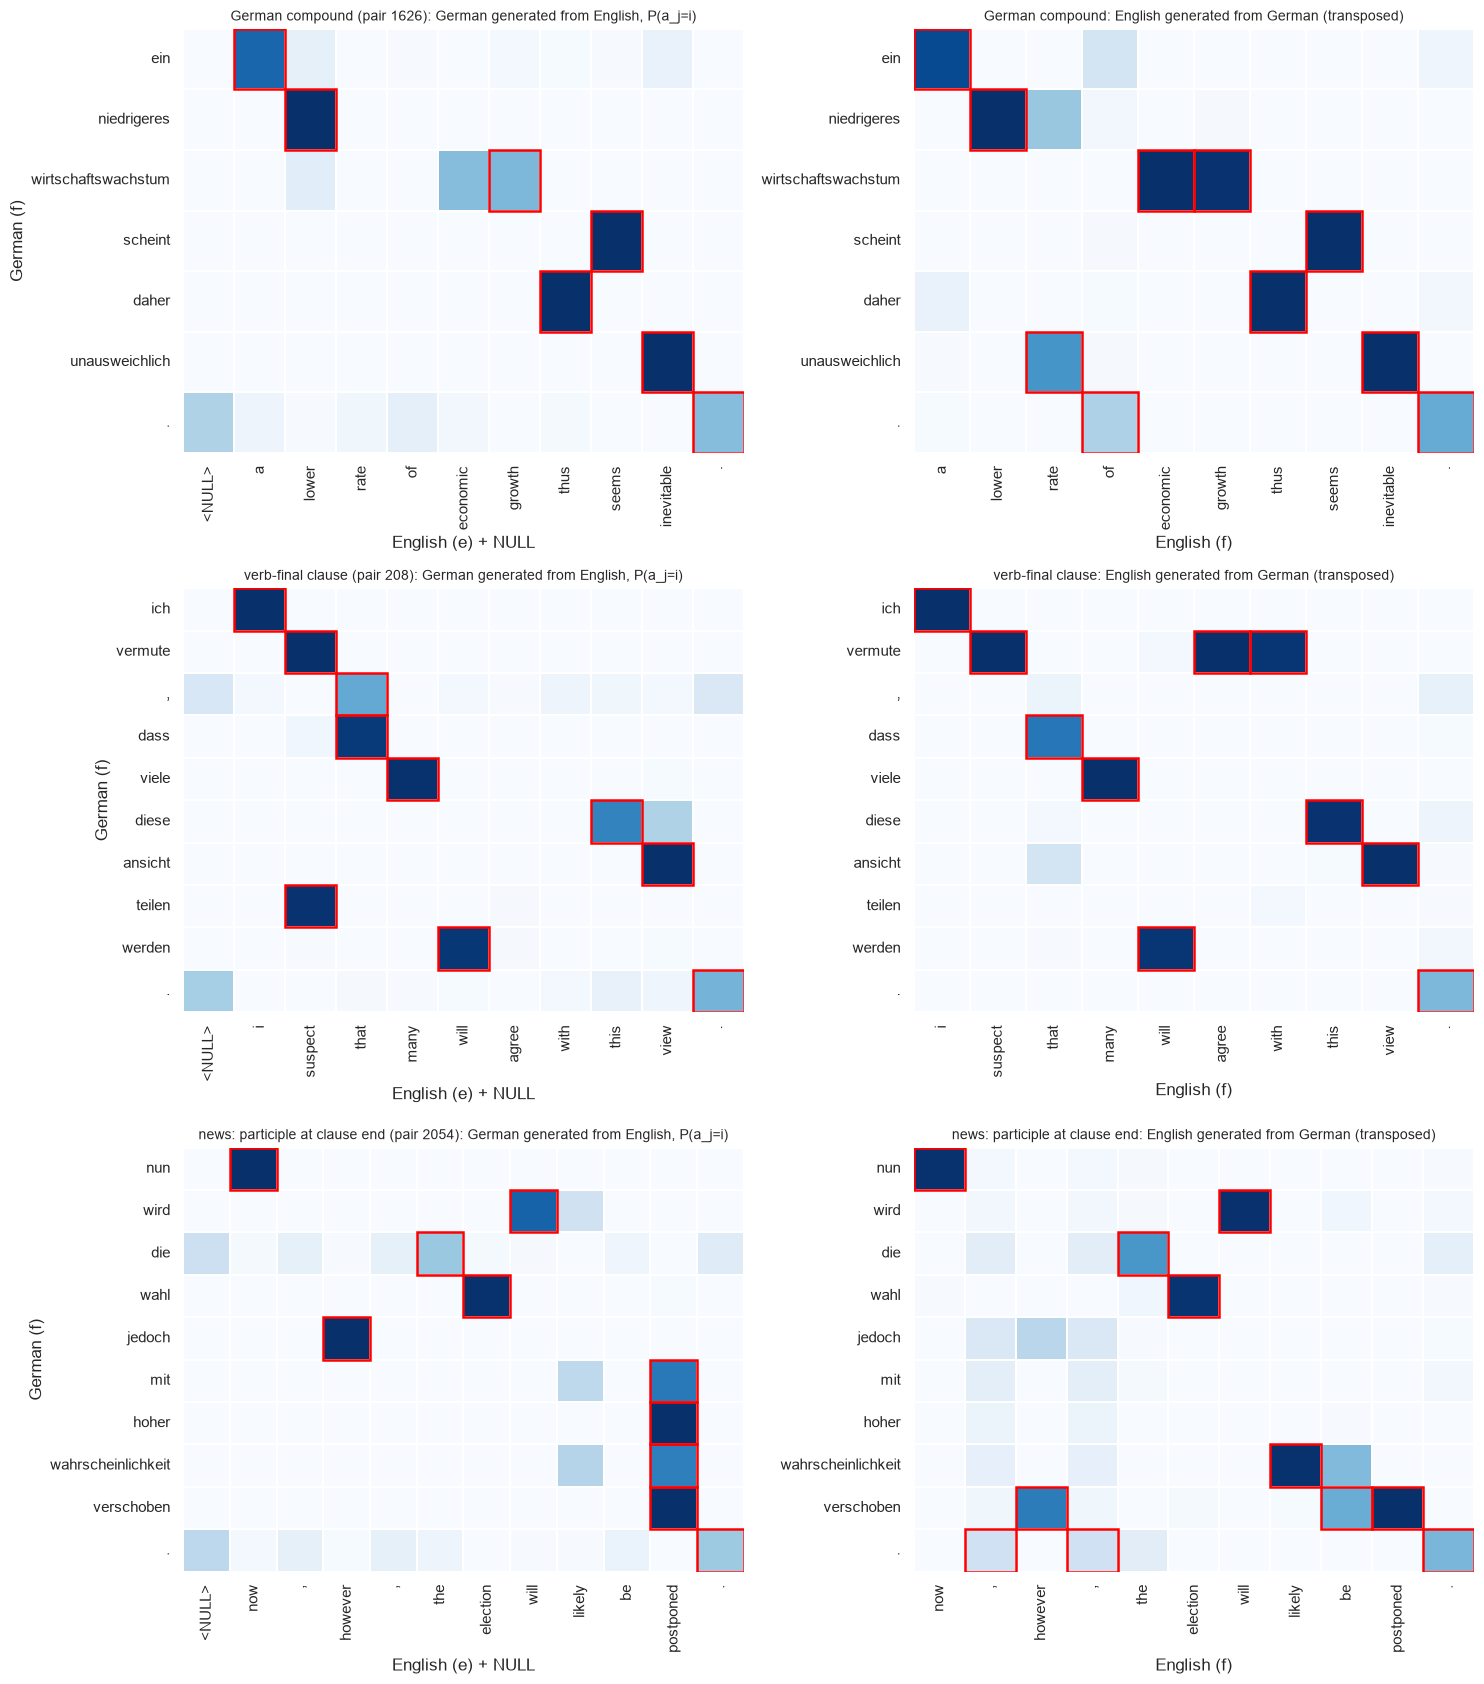

In [8]:
def find_pair(en_text, de_text):
    return next(k for k, (e, d) in enumerate(zip(train_en, train_de))
                if ' '.join(e) == en_text and ' '.join(d) == de_text)

HEATMAP_PAIRS = {
    'German compound': find_pair('a lower rate of economic growth thus seems inevitable .',
                                 'ein niedrigeres wirtschaftswachstum scheint daher unausweichlich .'),
    'verb-final clause': find_pair('i suspect that many will agree with this view .',
                                   'ich vermute , dass viele diese ansicht teilen werden .'),
    'news: participle at clause end': find_pair('now , however , the election will likely be postponed .',
                                                'nun wird die wahl jedoch mit hoher wahrscheinlichkeit verschoben .'),
}

def plot_alignment(ax, M, rows, cols, title, viterbi_axis=1):
    sns.heatmap(M, ax=ax, cmap='Blues', vmin=0, vmax=1, cbar=False, xticklabels=cols, yticklabels=rows,
                linewidths=.3, linecolor='white')
    best = M.argmax(viterbi_axis)
    for k, b in enumerate(best):
        r, c = (k, b) if viterbi_axis == 1 else (b, k)
        ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, ec='red', lw=1.8))
    ax.set_title(title, fontsize=10); ax.tick_params(axis='x', rotation=90)

fig, axes = plt.subplots(3, 2, figsize=(15, 17))
for row, (label, s) in enumerate(HEATMAP_PAIRS.items()):
    en_s, de_s = train_en[s], train_de[s]
    plot_alignment(axes[row, 0], m_de_en.posteriors(s), de_s, [NULL] + en_s,
                   f'{label} (pair {s}): German generated from English, P(a_j=i)')
    axes[row, 0].set(ylabel='German (f)', xlabel='English (e) + NULL')
    M = m_en_de.posteriors(s).T                           # rows: DE (+NULL), cols: EN
    plot_alignment(axes[row, 1], M[1:], de_s, en_s,
                   f'{label}: English generated from German (transposed)', viterbi_axis=0)
    axes[row, 1].set(xlabel='English (f)')
plt.tight_layout(); plt.savefig(FIG / 'B_alignment_heatmaps.png', dpi=110); plt.show()

In [9]:
def viterbi_links(model, s, f_sent, e_sent):
    return [(f, e_sent[a - 1] if a else NULL) for f, a in zip(f_sent, model.viterbi(s))]

for label, s in HEATMAP_PAIRS.items():
    print(f'--- {label}')
    print('  de <- en :', viterbi_links(m_de_en, s, train_de[s], train_en[s]))
    print('  en <- de :', viterbi_links(m_en_de, s, train_en[s], train_de[s]))

--- German compound
  de <- en : [('ein', 'a'), ('niedrigeres', 'lower'), ('wirtschaftswachstum', 'growth'), ('scheint', 'seems'), ('daher', 'thus'), ('unausweichlich', 'inevitable'), ('.', '.')]
  en <- de : [('a', 'ein'), ('lower', 'niedrigeres'), ('rate', 'unausweichlich'), ('of', '<NULL>'), ('economic', 'wirtschaftswachstum'), ('growth', 'wirtschaftswachstum'), ('thus', 'daher'), ('seems', 'scheint'), ('inevitable', 'unausweichlich'), ('.', '.')]
--- verb-final clause
  de <- en : [('ich', 'i'), ('vermute', 'suspect'), (',', 'that'), ('dass', 'that'), ('viele', 'many'), ('diese', 'this'), ('ansicht', 'view'), ('teilen', 'suspect'), ('werden', 'will'), ('.', '.')]
  en <- de : [('i', 'ich'), ('suspect', 'vermute'), ('that', 'dass'), ('many', 'viele'), ('will', 'werden'), ('agree', 'vermute'), ('with', 'vermute'), ('this', 'diese'), ('view', 'ansicht'), ('.', '.')]
--- news: participle at clause end
  de <- en : [('nun', 'now'), ('wird', 'will'), ('die', 'the'), ('wahl', 'election'),

### B.5 Limitations of IBM Model 1, shown on our own output

In [10]:
# (1) No fertility: a German compound can be generated from only ONE English word.
s = HEATMAP_PAIRS['German compound']
post = m_de_en.posteriors(s)
j = train_de[s].index('wirtschaftswachstum')
print('P(a_j = i) for f = "wirtschaftswachstum":',
      {e: round(p, 3) for e, p in zip([NULL] + train_en[s], post[j]) if p > 0.01})
print('t(wirtschaftswachstum | economic) =', round(m_de_en.prob('wirtschaftswachstum', 'economic'), 4),
      '| t(wirtschaftswachstum | growth) =', round(m_de_en.prob('wirtschaftswachstum', 'growth'), 4))

# Corpus-wide: for pairs where English has "economic growth" and German has "wirtschaftswachstum",
# how often does the de<-en Viterbi alignment link the compound to "economic" vs "growth"?
links = Counter()
for k, (e, d) in enumerate(zip(train_en, train_de)):
    if 'wirtschaftswachstum' in d and 'economic growth' in ' '.join(e):
        a = m_de_en.viterbi(k)[d.index('wirtschaftswachstum')]
        links[e[a - 1] if a else NULL] += 1
print('compound "wirtschaftswachstum" Viterbi-linked to:', dict(links))

P(a_j = i) for f = "wirtschaftswachstum": {'lower': np.float64(0.112), 'economic': np.float64(0.433), 'growth': np.float64(0.456)}
t(wirtschaftswachstum | economic) = 0.0664 | t(wirtschaftswachstum | growth) = 0.0699
compound "wirtschaftswachstum" Viterbi-linked to: {'growth': 27, 'mobilization': 1, 'propels': 1, 'bathwater': 1}


In [11]:
# (2) No distortion: Model 1 ignores word positions. Shuffling the German sentence leaves P(f|e) unchanged
#     and simply permutes the rows of the posterior matrix -- the verb-final order is invisible to the model.
s = HEATMAP_PAIRS['verb-final clause']
en_s, de_s = train_en[s], train_de[s]
rng = random.Random(SEED)
shuffled = de_s[:]; rng.shuffle(shuffled)

def sent_loglik(model, fs, es):
    T = np.array([[model.prob(f, e) for e in [NULL] + es] for f in fs])
    return float(np.log(T.sum(1)).sum() - len(fs) * math.log(len(es) + 1))

print('original :', ' '.join(de_s), f'  log P(f|e) = {sent_loglik(m_de_en, de_s, en_s):.4f}')
print('shuffled :', ' '.join(shuffled), f'  log P(f|e) = {sent_loglik(m_de_en, shuffled, en_s):.4f}')

# Identical words get identical posteriors wherever they stand, so positional ties cannot be resolved.
k = next(k for k, (e, d) in enumerate(zip(train_en, train_de))
         if 8 <= len(d) <= 14 and d.count('die') >= 2 and e.count('the') >= 2)
P = m_de_en.posteriors(k); rows = [j for j, w in enumerate(train_de[k]) if w == 'die']
print(f'\npair {k}:', ' '.join(train_en[k]), '|||', ' '.join(train_de[k]))
print('"die" at German positions', rows, '-> Viterbi English positions',
      [int(m_de_en.viterbi(k)[j]) for j in rows], '(identical rows:',
      bool(np.allclose(P[rows[0]], P[rows[1]])), ')')

original : ich vermute , dass viele diese ansicht teilen werden .   log P(f|e) = -31.6711
shuffled : teilen dass , werden diese ansicht . viele ich vermute   log P(f|e) = -31.6711

pair 355: since then , however , the sd has fundamentally changed the country 's political landscape . ||| seitdem jedoch hat die sd die politische landschaft des landes grundlegend verändert .
"die" at German positions [3, 5] -> Viterbi English positions [6, 6] (identical rows: True )


In [12]:
# (3) NULL word and the garbage-collector effect of rare words.
freq_en = Counter(w for s in train_en for w in s)
fert = defaultdict(list)            # Viterbi fertility (#German words linked) per English token, by frequency band
null_words = Counter()
for k, (e, d) in enumerate(zip(train_en, train_de)):
    a = m_de_en.viterbi(k)
    n_linked = Counter(a)
    for i, w in enumerate(e, start=1):
        band = '1 (singleton)' if freq_en[w] == 1 else '2-5' if freq_en[w] <= 5 else '6-100' if freq_en[w] <= 100 else '>100'
        fert[band].append(n_linked[i])
    null_words.update(d[j] for j in range(len(d)) if a[j] == 0)
gc = pd.DataFrame({band: {'English tokens': len(v), 'mean Viterbi fertility': round(np.mean(v), 3),
                          'share with fertility >= 3 (%)': round(100 * np.mean(np.array(v) >= 3), 2)}
                   for band, v in sorted(fert.items())}).T
n_de_tokens = sum(map(len, train_de))
print(f'German tokens aligned to NULL: {sum(null_words.values()):,} / {n_de_tokens:,} '
      f'({100 * sum(null_words.values()) / n_de_tokens:.1f}%); most frequent: {null_words.most_common(10)}')
gc

German tokens aligned to NULL: 1,391 / 179,687 (0.8%); most frequent: [('die', 853), ('der', 243), (',', 229), ('.', 31), ('in', 21), ('das', 8), ('und', 3), ('zu', 1), ('sich', 1), ('ist', 1)]


,English tokens,mean Viterbi fertility,share with fertility >= 3 (%)
1 (singleton),7336.0,4.411,60.62
2-5,13558.0,1.893,25.07
6-100,56222.0,0.877,4.23
>100,101158.0,0.702,2.19


In [13]:
# A concrete garbage-collector example: the singleton English word that "collects" the most German words.
best = None
for k, (e, d) in enumerate(zip(train_en, train_de)):
    if len(e) > 15: continue
    a = m_de_en.viterbi(k); n_linked = Counter(a)
    for i, w in enumerate(e, start=1):
        if freq_en[w] == 1 and (best is None or n_linked[i] > best[0]):
            best = (n_linked[i], k, w)
n, k, w = best
print(f'pair {k}:\n  EN: {" ".join(train_en[k])}\n  DE: {" ".join(train_de[k])}')
print(f'singleton "{w}" is the Viterbi link of {n} German words:',
      [d for d, a in zip(train_de[k], m_de_en.viterbi(k)) if a and train_en[k][a - 1] == w])
print(f'top t(. | {w}):', [(f, round(p, 3)) for f, p in m_de_en.top_translations(w, 8)])

pair 9940:
  EN: the beatles used to sing that " money can 't buy love . "
  DE: die beatles sangen " money can ' t buy love " - für geld gibt ' s keine liebe zu kaufen .
singleton "beatles" is the Viterbi link of 13 German words: ['beatles', 'sangen', 'money', 'can', "'", 't', 'buy', 'love', '-', 'für', 'gibt', "'", 's']
top t(. | beatles): [("'", 0.151), ('love', 0.075), ('t', 0.075), ('can', 0.075), ('buy', 0.075), ('sangen', 0.075), ('beatles', 0.075), ('s', 0.075)]


**Discussion of limitations (with the evidence above).**
1. **No fertility (one-to-many).** Under the de←en model, each German word is generated by exactly one English
   word. The compound *wirtschaftswachstum* therefore links to *growth* **or** to *economic*, never to both, and
   the other English word looks untranslated. Across the corpus, the compound is linked to *growth* in 27 of 30
   pairs and never to both words. Its $t$ mass is split between the two English words, so neither
   explains the compound well. The same happens for *zentralbank* (*central bank*), *finanzkrise* (*financial
   crisis*) and *Bundesverfassungsgericht* (*Federal Constitutional Court*, three English words, and not even in
   our training data). This is the motivation for fertility in IBM Model 3, and here for phrase extraction on
   symmetrized alignments in Part C.
2. **No distortion (reordering).** The shuffled German sentence gets *exactly* the same likelihood as the
   original one. The model cannot tell that *teilen werden* is verb-final (the de←en Viterbi alignment even links
   *teilen* to *suspect* instead of *agree*), or that *verschoben* belongs at the
   end of the clause. Two copies of *die* get identical posterior rows, so their Viterbi links are the same no
   matter where they stand. Alignment comes from lexical co-occurrence only, so frequent words such as
   *die/der*, commas and auxiliaries align almost at random between their candidates. IBM Model 2 (absolute
   distortion) and the HMM alignment model (relative jumps) address this.
3. **NULL word and the garbage-collector effect.** NULL is rarely the Viterbi choice: only 0.8% of German tokens
   are aligned to it, almost all of them articles (*die, der*) and punctuation. NULL competes with every real
   English word in the sentence and loses to any word that co-occurs often, so German articles are usually
   forced onto some English noun or onto *the*, even when English has no article. In the other direction, rare
   English words act as **garbage collectors**: a singleton has only one sentence to explain. EM can raise its
   $t$ for several co-occurring German words at once without hurting any other sentence, so singletons have a
   much higher mean Viterbi fertility than frequent words (table above), and the concrete example shows a
   singleton absorbing several unrelated German words. With 60% singleton German types (Part A), this noise
   goes straight into the phrase table.
4. **Asymmetry.** The two directions produce different alignments (see the right-hand heatmaps). Neither is a
   valid many-to-many alignment, which is why Part C symmetrizes them.

## Part C — Phrase-based SMT

### C.1 Viterbi alignments and symmetrization
For every training pair we take the Viterbi alignment of each direction and combine them (Och & Ney 2003):
* **intersection**: links found by both directions. High precision, but very sparse.
* **union**: links found by either direction. High recall, but noisy, and it blocks many phrase pairs.
* **grow-diag-final** (Koehn et al. 2003): start from the intersection, add neighbouring union links
  (including diagonal neighbours) that connect a still-unaligned word, then add any remaining union link whose
  English and German words are both unaligned.

In [14]:
NEIGHBOURS = [(-1, 0), (0, -1), (1, 0), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]

def directional_links(s):
    """Viterbi links of both directions as sets of (en_pos, de_pos), 0-based, NULL links dropped."""
    a_de = m_de_en.viterbi(s)       # for every German position j: aligned English position (1-based, 0 = NULL)
    a_en = m_en_de.viterbi(s)       # for every English position i: aligned German position
    de_en = {(int(i) - 1, j) for j, i in enumerate(a_de) if i > 0}
    en_de = {(i, int(j) - 1) for i, j in enumerate(a_en) if j > 0}
    return de_en, en_de

def symmetrize(A1, A2, n_en, n_de, method='grow-diag-final'):
    inter, union = A1 & A2, A1 | A2
    if method == 'intersection': return inter
    if method == 'union': return union
    A = set(inter)
    en_al, de_al = Counter(i for i, _ in A), Counter(j for _, j in A)
    def add(i, j):
        A.add((i, j)); en_al[i] += 1; de_al[j] += 1
    grown = True
    while grown:                                   # grow-diag
        grown = False
        for i, j in sorted(A):
            for di, dj in NEIGHBOURS:
                ni, nj = i + di, j + dj
                if (0 <= ni < n_en and 0 <= nj < n_de and (ni, nj) in union and (ni, nj) not in A
                        and (en_al[ni] == 0 or de_al[nj] == 0)):
                    add(ni, nj); grown = True
    if method == 'grow-diag': return A
    for i, j in sorted(union):                     # final-and
        if en_al[i] == 0 and de_al[j] == 0:
            add(i, j)
    return A

SYM_METHODS = ['intersection', 'grow-diag-final', 'union']
alignments = {m: [] for m in SYM_METHODS}
for s, (e, d) in enumerate(zip(train_en, train_de)):
    A1, A2 = directional_links(s)
    for m in SYM_METHODS:
        alignments[m].append(symmetrize(A1, A2, len(e), len(d), m))

n_en_tok, n_de_tok = sum(map(len, train_en)), sum(map(len, train_de))
sym_stats = pd.DataFrame({m: {
    'alignment points': sum(map(len, A)),
    'points / sentence': round(np.mean(list(map(len, A))), 2),
    'unaligned EN tokens (%)': round(100 * (1 - sum(len({i for i, _ in a}) for a in A) / n_en_tok), 1),
    'unaligned DE tokens (%)': round(100 * (1 - sum(len({j for _, j in a}) for a in A) / n_de_tok), 1),
} for m, A in alignments.items()}).T
sym_stats

,alignment points,points / sentence,unaligned EN tokens (%),unaligned DE tokens (%)
intersection,90310.0,9.03,49.3,49.7
grow-diag-final,159255.0,15.93,22.6,23.6
union,265022.0,26.50,0.7,0.8


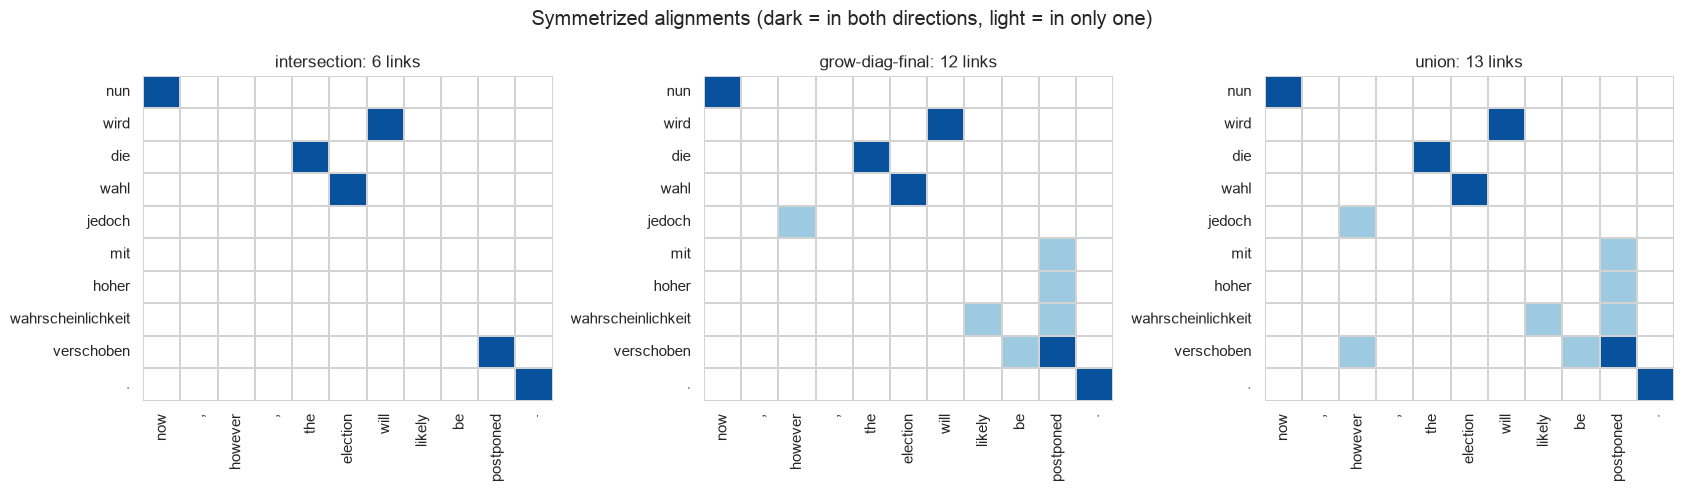

In [15]:
s = HEATMAP_PAIRS['news: participle at clause end']
e, d = train_en[s], train_de[s]
A1, A2 = directional_links(s)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, m in zip(axes, SYM_METHODS):
    M = np.zeros((len(d), len(e)))
    for i, j in alignments[m][s]:
        M[j, i] = 1 + ((i, j) in A1 and (i, j) in A2)       # 2 = both directions agree
    sns.heatmap(M, ax=ax, cmap=sns.color_palette(['white', '#9ecae1', '#08519c'], as_cmap=True), vmin=0, vmax=2,
                cbar=False, xticklabels=e, yticklabels=d, linewidths=.3, linecolor='lightgray')
    ax.set_title(f'{m}: {len(alignments[m][s])} links'); ax.tick_params(axis='x', rotation=90)
fig.suptitle('Symmetrized alignments (dark = in both directions, light = in only one)')
plt.tight_layout(); plt.savefig(FIG / 'C_symmetrization.png', dpi=110); plt.show()

**Choice: grow-diag-final.** The intersection leaves about half of the tokens unaligned, and phrase
extraction then attaches them freely to neighbouring phrases, which produces many loose and over-long phrase
pairs. The union is dense but contains the Model 1 noise from both directions (garbage-collector links, random
article links), and its inconsistent links rule out many correct phrase pairs. Grow-diag-final keeps the
reliable intersection as its backbone and adds union links only next to existing links or for still-unaligned
words. It is the standard Moses default and the best trade-off in Koehn et al. (2003). The extraction counts
below make the trade-off visible.

### C.2 Phrase extraction (Koehn, Och & Marcu 2003)
A phrase pair $(\bar e_{i_1..i_2}, \bar d_{j_1..j_2})$ is **consistent** with alignment $A$ if it contains at
least one link and no word inside the pair is linked to a word outside it. We enumerate English spans of up to
`MAX_PHRASE_LEN` = 4 words, take the minimal German span covering their links, reject the pair if a German word
in that span links outside the English span, and then extend the German side over neighbouring **unaligned**
words (still ≤ 4 words).

In [16]:
def extract_phrases(e, d, A, max_len=C['MAX_PHRASE_LEN']):
    """All phrase pairs (en_phrase, de_phrase) consistent with alignment A (set of (en_pos, de_pos))."""
    de_aligned = Counter(j for _, j in A)
    pairs = []
    for i1 in range(len(e)):
        for i2 in range(i1, min(len(e), i1 + max_len)):
            js = [j for i, j in A if i1 <= i <= i2]
            if not js:
                continue
            j1, j2 = min(js), max(js)
            if j2 - j1 >= max_len:
                continue
            if any(j1 <= j <= j2 and not i1 <= i <= i2 for i, j in A):     # consistency check
                continue
            src = ' '.join(e[i1:i2 + 1])
            js_ = j1
            while js_ >= 0 and (js_ == j1 or de_aligned[js_] == 0):         # extend over unaligned DE words
                je_ = j2
                while je_ < len(d) and (je_ == j2 or de_aligned[je_] == 0) and je_ - js_ < max_len:
                    pairs.append((src, ' '.join(d[js_:je_ + 1])))
                    je_ += 1
                js_ -= 1
    return pairs

phrase_counts, extraction_stats = {}, {}
for m in SYM_METHODS:
    t0 = time.perf_counter()
    cnt = Counter()
    for e, d, A in zip(train_en, train_de, alignments[m]):
        cnt.update(extract_phrases(e, d, A))
    phrase_counts[m] = cnt
    extraction_stats[m] = {'phrase pair tokens': sum(cnt.values()), 'unique phrase pairs': len(cnt),
                           'unique EN phrases': len({p for p, _ in cnt}), 'seconds': round(time.perf_counter() - t0, 1)}
pd.DataFrame(extraction_stats).T

,phrase pair tokens,unique phrase pairs,unique EN phrases,seconds
intersection,1244534.0,1090147.0,240090.0,1.1
grow-diag-final,529053.0,412345.0,143044.0,1.1
union,82855.0,22112.0,18753.0,1.0


In [17]:
pairs = phrase_counts[SMT['SYMMETRIZATION']]
print(f'Using {SMT["SYMMETRIZATION"]}: extracted {sum(pairs.values()):,} phrase-pair tokens, '
      f'{len(pairs):,} unique phrase pairs (max length {C["MAX_PHRASE_LEN"]}).')
len_dist = pd.crosstab(pd.Series([len(p.split()) for p, _ in pairs], name='EN length'),
                       pd.Series([len(q.split()) for _, q in pairs], name='DE length'))
len_dist

Using grow-diag-final: extracted 529,053 phrase-pair tokens, 412,345 unique phrase pairs (max length 4).


DE length,1,2,3,4
EN length,,,,
1,14579,35084,22062,11105
2,33148,50252,33506,18139
3,21213,33032,37720,24172
4,10851,17576,24177,25729


### C.3 Phrase translation table
With $f$ the English source phrase and $e$ the German target phrase (noisy-channel notation):

* $\phi(f \mid e) = \dfrac{\text{count}(e, f)}{\text{count}(e)}$, the **noisy-channel translation model**
  $P(\text{en} \mid \text{de})$ from the assignment formula.
* $\phi(e \mid f) = \dfrac{\text{count}(e, f)}{\text{count}(f)}$, the **inverse (direct) model**, added as a second
  feature, as in Moses.

The table is indexed by English phrase, because the decoder looks up translation options for source spans. It is
**pruned to the top `TABLE_LIMIT` = 20 German options** per English phrase, ranked by the direct probability
$\phi(e\mid f)$. We do not rank by $\phi(f\mid e)$, because a German phrase seen only once gets
$\phi(f\mid e) = 1$ (e.g. *the government → der regierungsverhältnisse*), and such noisy singletons would push
out the frequent, correct options.

In [18]:
def build_phrase_table(pair_counts, table_limit=SMT['TABLE_LIMIT']):
    cnt_f, cnt_e = Counter(), Counter()                  # f = English phrase, e = German phrase
    for (f, e), c in pair_counts.items():
        cnt_f[f] += c; cnt_e[e] += c
    table = defaultdict(list)
    for (f, e), c in pair_counts.items():
        table[f].append((tuple(e.split()), math.log(c / cnt_e[e]), math.log(c / cnt_f[f]), c))
    for f in table:
        table[f].sort(key=lambda o: -o[2])                 # rank by phi(e|f): robust to rare German phrases
        del table[f][table_limit:]
    return dict(table)

phrase_table = build_phrase_table(pairs)
print(f'phrase table: {len(phrase_table):,} English phrases, '
      f'{sum(map(len, phrase_table.values())):,} entries after top-{SMT["TABLE_LIMIT"]} pruning')

def show_options(f, k=5):
    return pd.DataFrame([(f, ' '.join(e), round(math.exp(a), 3), round(math.exp(b), 3), c)
                         for e, a, b, c in phrase_table.get(f, [])[:k]],
                        columns=['EN phrase f', 'DE phrase e', 'phi(f|e)', 'phi(e|f)', 'count'])

pd.concat([show_options(f, 4) for f in ['the government', 'central bank', 'economic growth',
                                         'the financial crisis', 'said that', 'will be']], ignore_index=True)

phrase table: 143,044 English phrases, 361,832 entries after top-20 pruning


,EN phrase f,DE phrase e,phi(f|e),phi(e|f),count
0,the government,die regierung,0.319,0.345,30
1,the government,regierung,0.035,0.126,11
2,the government,der regierung,0.085,0.046,4
3,the government,", die regierung",0.500,0.023,2
4,central bank,zentralbank,0.568,0.525,21
5,central bank,der zentralbanken,0.222,0.050,2
6,central bank,zentralbanken,0.069,0.050,2
7,central bank,notenbanken,0.167,0.025,1
8,economic growth,wirtschaftswachstum,0.525,0.309,21
9,economic growth,das wirtschaftswachstum,0.417,0.074,5


### C.4 German trigram language model (interpolated Kneser–Ney, own implementation)
We implement **interpolated Kneser–Ney** (Kneser & Ney 1995; Chen & Goodman 1999) with one absolute discount
$D = 0.75$:

$$P_{KN}(w \mid u v) = \frac{\max(c(uvw) - D, 0)}{c(uv\cdot)} + \frac{D\,N_{1+}(uv\cdot)}{c(uv\cdot)}\,P_{KN}(w \mid v)$$

Lower orders use **continuation counts** $N_{1+}(\cdot\, v w)$ instead of raw counts. The recursion ends in a
uniform distribution over the vocabulary plus `<unk>`. Unseen contexts fall back to the next lower order.

*Why not `nltk.lm.KneserNeyInterpolated`?* It gives the same estimates in principle, but it recomputes each
probability recursively without caching. The decoder makes millions of LM queries, so NLTK would make the beam
sweep take hours. Our version stores the count tables in dictionaries and memoises queries. As a sanity check,
we verify that the probabilities for a given context sum to 1.

In [19]:
class KneserNeyLM:
    BOS, EOS, UNK = '<s>', '</s>', '<unk>'

    def __init__(self, sents, order=C['LM_ORDER'], discount=SMT['KN_DISCOUNT']):
        self.n, self.D = order, discount
        self.vocab = {w for s in sents for w in s} | {self.EOS, self.UNK}
        self.counts = [Counter() for _ in range(order + 1)]       # counts[m][ngram]
        for s in sents:
            toks = [self.BOS] * (order - 1) + s + [self.EOS]
            for k in range(order - 1, len(toks)):
                self.counts[order][tuple(toks[k - order + 1:k + 1])] += 1
        for m in range(order - 1, 0, -1):                          # continuation counts N1+(. w_2..w_m)
            for g in self.counts[m + 1]:
                self.counts[m][g[1:]] += 1
        self.ctx_total = [Counter() for _ in range(order + 1)]
        self.ctx_types = [Counter() for _ in range(order + 1)]
        for m in range(1, order + 1):
            for g, c in self.counts[m].items():
                self.ctx_total[m][g[:-1]] += c
                self.ctx_types[m][g[:-1]] += 1
        self._cache = {}

    def prob(self, w, ctx):
        """P(w | ctx) where ctx is a tuple of the (n-1) previous tokens."""
        key = (w, ctx)
        p = self._cache.get(key)
        if p is not None:
            return p
        w_ = w if w in self.vocab else self.UNK
        p = 1.0 / len(self.vocab)
        for m in range(1, self.n + 1):
            h = tuple(ctx[len(ctx) - m + 1:]) if m > 1 else ()
            if len(h) != m - 1:
                break
            tot = self.ctx_total[m].get(h, 0)
            if tot == 0:
                break                                           # unseen context: keep the lower-order estimate
            p = max(self.counts[m].get(h + (w_,), 0) - self.D, 0) / tot + self.D * self.ctx_types[m][h] / tot * p
        self._cache[key] = p
        return p

    def logprob(self, w, ctx):
        return math.log(self.prob(w, ctx))

    def sentence_logprob(self, s):
        ctx, lp = (self.BOS,) * (self.n - 1), 0.0
        for w in s + [self.EOS]:
            lp += self.logprob(w, ctx); ctx = ctx[1:] + (w,)
        return lp

    def perplexity(self, sents):
        return math.exp(-sum(self.sentence_logprob(s) for s in sents) / sum(len(s) + 1 for s in sents))

class AddKTrigramLM(KneserNeyLM):
    """Baseline for comparison: add-k smoothed trigram (no interpolation)."""
    def __init__(self, sents, k=0.01):
        super().__init__(sents, order=3); self.k = k
        self.raw2 = Counter()
        for g, c in self.counts[3].items():
            self.raw2[g[:2]] += c
    def prob(self, w, ctx):
        w_ = w if w in self.vocab else self.UNK
        return (self.counts[3].get(tuple(ctx[-2:]) + (w_,), 0) + self.k) / (self.raw2.get(tuple(ctx[-2:]), 0) + self.k * len(self.vocab))

t0 = time.perf_counter()
lm = KneserNeyLM(train_de)
print(f'KN trigram LM trained on {len(train_de):,} German sentences in {time.perf_counter() - t0:.1f}s; '
      f'|V| = {len(lm.vocab):,}; {len(lm.counts[3]):,} trigram types')
for ctx in [('die', 'regierung'), ('<s>', '<s>'), ('nie', 'gesehen')]:
    print(f'  sum_w P(w | {ctx}) = {sum(lm.prob(w, ctx) for w in lm.vocab):.6f}')

oov_rate = 100 * np.mean([w not in lm.vocab for s in lm_heldout for w in s])
lm_table = pd.DataFrame({
    'held-out perplexity (lm_heldout.tok.de)': {
        'KN trigram (ours)': lm.perplexity(lm_heldout),
        'KN bigram (ours)': KneserNeyLM(train_de, order=2).perplexity(lm_heldout),
        'add-0.01 trigram': AddKTrigramLM(train_de, 0.01).perplexity(lm_heldout),
        'add-1 trigram': AddKTrigramLM(train_de, 1.0).perplexity(lm_heldout)},
    'training perplexity (first 500 train sents)': {
        'KN trigram (ours)': lm.perplexity(train_de[:500]), 'KN bigram (ours)': np.nan,
        'add-0.01 trigram': np.nan, 'add-1 trigram': np.nan}}).round(1)
print(f'held-out OOV token rate: {oov_rate:.2f}% (mapped to <unk>)')
lm_table

KN trigram LM trained on 10,000 German sentences in 0.2s; |V| = 23,199; 157,831 trigram types


  sum_w P(w | ('die', 'regierung')) = 1.000000
  sum_w P(w | ('<s>', '<s>')) = 1.000000
  sum_w P(w | ('nie', 'gesehen')) = 1.000000


held-out OOV token rate: 7.26% (mapped to <unk>)


,held-out perplexity (lm_heldout.tok.de),training perplexity (first 500 train sents)
KN trigram (ours),481.9,8.6
KN bigram (ours),493.2,NaN
add-0.01 trigram,7429.5,NaN
add-1 trigram,14563.6,NaN


**LM results.** The interpolated KN trigram reaches a held-out perplexity of about **480** on
`lm_heldout.tok.de`, which is in the expected range for a 180k-token training corpus with ~7.5% OOV tokens. It
beats the KN bigram (the trigram context helps even with this little data) and is far better than add-k
smoothing: add-1 gives a huge share of the probability mass to the ~23k × 23k unseen continuations. The large gap
between training perplexity (≈9) and held-out perplexity shows how sparse German trigrams are at this corpus
size. This weak LM is one of the main limits on SMT fluency below.

### C.5 Decoder (own implementation): stack decoding with beam search
We use a phrase-based **stack decoder** in the style of Koehn (2004) and Collins' notes. A hypothesis is
(coverage bit-vector of the English words already translated, last two German words, end of the last
translated source span, score). Stack $k$ holds hypotheses that cover $k$ source words.

**Score** (log-linear, an extension of the assignment's two-feature formula, with e = German, f = English):

$$\text{score}(e) = \lambda_1 \log \phi(f\mid e) + \lambda_{inv} \log \phi(e\mid f) + \lambda_2 \log P_{LM}(e)
                  + \lambda_{wp}\,|e| - \lambda_{d} \sum |\text{start}_k - \text{end}_{k-1}|$$

* **Translation options** for every span of up to 4 English words come from the phrase table.
  An **unknown source word** has no option, so it is **passed through unchanged** with a fixed penalty
  (`OOV_PENALTY`). This matters for names and numbers, and for the OOV analysis in Part D.
* **Reordering**: limited jumps (distortion limit 4) with a linear distortion penalty. Hypotheses that can no
  longer reach the leftmost untranslated word are not created, so the search never hits a dead end.
* **Future-cost estimate** for the uncovered spans (best TM + in-phrase LM score per span, combined by dynamic
  programming), so hypotheses that translated easy and hard parts are ranked fairly within a stack.
* **Recombination**: hypotheses with the same coverage, LM state and last position are merged, keeping the best.
* **Beam (histogram pruning)**: only the `beam` best hypotheses of each stack (by score + future cost) are
  expanded. `beam = 1` is a greedy decoder.

In [20]:
class StackDecoder:
    def __init__(self, phrase_table, lm, weights, max_phrase_len=C['MAX_PHRASE_LEN'],
                 distortion_limit=SMT['DISTORTION_LIMIT'], oov_penalty=SMT['OOV_PENALTY']):
        self.pt, self.lm, self.w = phrase_table, lm, weights
        self.L, self.dl, self.oov_penalty = max_phrase_len, distortion_limit, oov_penalty

    def _options(self, src):
        """(i, j) -> list of (german tuple, weighted TM + word-penalty score)."""
        w, opts, n = self.w, {}, len(src)
        for i in range(n):
            for j in range(i + 1, min(n, i + self.L) + 1):
                entry = self.pt.get(' '.join(src[i:j]))
                if entry:
                    opts[(i, j)] = [(e, w['tm'] * a + w['tm_inv'] * b + w['wp'] * len(e)) for e, a, b, _ in entry]
            if (i, i + 1) not in opts:                          # unknown word -> pass through unchanged
                opts[(i, i + 1)] = [((src[i],), self.oov_penalty + w['wp'])]
        return opts

    def _future_costs(self, opts, n):
        fc = np.full((n + 1, n + 1), -np.inf)
        for (i, j), ol in opts.items():
            for e, s in ol:
                lm_est, ctx = 0.0, ()
                for word in e:
                    lm_est += self.lm.logprob(word, ctx); ctx = (ctx + (word,))[-2:]
                fc[i, j] = max(fc[i, j], s + self.w['lm'] * lm_est)
        for length in range(2, n + 1):
            for i in range(n - length + 1):
                j = i + length
                for k in range(i + 1, j):
                    fc[i, j] = max(fc[i, j], fc[i, k] + fc[k, j])
        return fc

    def translate(self, src, beam=5):
        n = len(src)
        if n == 0:
            return []
        opts = self._options(src)
        fc = self._future_costs(opts, n)
        spans = sorted(opts)
        full = (1 << n) - 1

        def future(cov):
            total, i = 0.0, 0
            while i < n:
                if cov >> i & 1:
                    i += 1; continue
                j = i
                while j < n and not cov >> j & 1:
                    j += 1
                total += fc[i, j]; i = j
            return total

        def first_gap(cov):
            return (~cov & (cov + 1)).bit_length() - 1

        # stacks[k]: (coverage, lm_state, last_end) -> (score, score + future, output words)
        stacks = [dict() for _ in range(n + 1)]
        stacks[0][(0, (KneserNeyLM.BOS,) * 2, 0)] = (0.0, future(0), ())
        w_lm, w_d = self.w['lm'], self.w['dist']
        for k in range(n):
            if not stacks[k]:
                continue
            survivors = sorted(stacks[k].items(), key=lambda kv: -kv[1][1])[:beam]
            for (cov, ctx, last), (score, _, words) in survivors:
                gap = first_gap(cov)
                for (i, j) in spans:
                    if i - gap > self.dl or abs(i - last) > self.dl:
                        continue
                    mask = ((1 << j) - 1) ^ ((1 << i) - 1)
                    if cov & mask:
                        continue
                    ncov = cov | mask
                    if ncov != full:
                        ngap = first_gap(ncov)
                        if ngap < i and j - ngap > self.dl:       # leftmost gap would become unreachable
                            continue
                    nk = k + (j - i)
                    base = score - w_d * abs(i - last)
                    fut = future(ncov)
                    for e, s in opts[(i, j)]:
                        lm_s, c = 0.0, ctx
                        for word in e:
                            lm_s += self.lm.logprob(word, c); c = (c[1], word)
                        if ncov == full:
                            lm_s += self.lm.logprob(KneserNeyLM.EOS, c)
                        ns = base + s + w_lm * lm_s
                        key = (ncov, c, j)
                        old = stacks[nk].get(key)
                        if old is None or old[0] < ns:             # recombination
                            stacks[nk][key] = (ns, ns + fut, words + e)
        if not stacks[n]:                                       # safety net (not expected to trigger)
            return [w for i in range(n) for w in opts[(i, i + 1)][0][0]]
        return list(max(stacks[n].values(), key=lambda h: h[0])[2])

def detok(tokens):
    return DETOK.detokenize(tokens)

def sacre_bleu(hyps_detok, refs_raw):
    """Case-insensitive sacreBLEU (13a) on detokenized text -- the same metric as Part D."""
    return sacrebleu.corpus_bleu(hyps_detok, [refs_raw], lowercase=True).score

### C.6 Weight tuning on a development slice (not the test set)
To keep the test set clean, we hold out the **last 300 training pairs** as a development set. We rebuild the
whole pipeline (IBM Model 1 in both directions, grow-diag-final, extraction, phrase table, KN LM) on the
remaining 9,700 pairs and grid-search the LM weight, the word penalty and the distortion weight at beam 5
($\lambda_{tm} = \lambda_{inv} = 1$ fixed). The best weights are then used with the full 10k-pair model.
This is a small stand-in for MERT (Och 2003).

In [21]:
def build_pipeline(en_sents, de_sents, iters=C['EM_ITERS'], sym=SMT['SYMMETRIZATION']):
    """Parts B + C end to end: IBM1 x 2 -> Viterbi -> symmetrize -> extract -> phrase table, plus KN LM."""
    mde, men = IBMModel1(de_sents, en_sents), IBMModel1(en_sents, de_sents)
    mde.train(iters); men.train(iters)
    cnt = Counter()
    for s, (e, d) in enumerate(zip(en_sents, de_sents)):
        a_de, a_en = mde.viterbi(s), men.viterbi(s)
        A1 = {(int(i) - 1, j) for j, i in enumerate(a_de) if i > 0}
        A2 = {(i, int(j) - 1) for i, j in enumerate(a_en) if j > 0}
        cnt.update(extract_phrases(e, d, symmetrize(A1, A2, len(e), len(d), sym)))
    return build_phrase_table(cnt), KneserNeyLM(de_sents)

n_dev = SMT['N_DEV']
t0 = time.perf_counter()
dev_pt, dev_lm = build_pipeline(train_en[:-n_dev], train_de[:-n_dev])
dev_src, dev_ref = train_en[-n_dev:], train_de[-n_dev:]
print(f'tuning pipeline rebuilt on {len(train_en) - n_dev:,} pairs in {time.perf_counter() - t0:.1f}s')

grid = []
t0 = time.perf_counter()
for lam_lm in [0.5, 1.0, 1.5]:
    for wp in [-0.5, 0.0, 0.5, 1.0]:
        for dist in [0.25, 0.5]:
            W = dict(tm=1.0, tm_inv=1.0, lm=lam_lm, wp=wp, dist=dist)
            dec = StackDecoder(dev_pt, dev_lm, W)
            hyps = [dec.translate(s, beam=5) for s in dev_src]
            grid.append({**W, 'dev BLEU': sacrebleu.corpus_bleu([' '.join(h) for h in hyps],
                                                                 [[' '.join(r) for r in dev_ref]], tokenize='none').score,
                         'len ratio': sum(map(len, hyps)) / sum(map(len, dev_ref))})
grid = pd.DataFrame(grid).sort_values('dev BLEU', ascending=False).reset_index(drop=True)
WEIGHTS = grid.iloc[0][['tm', 'tm_inv', 'lm', 'wp', 'dist']].astype(float).to_dict()
print(f'{len(grid)} weight settings decoded in {time.perf_counter() - t0:.0f}s; chosen weights: {WEIGHTS}')
del dev_pt, dev_lm
grid.head(8).round(3)

tuning pipeline rebuilt on 9,700 pairs in 5.1s


24 weight settings decoded in 39s; chosen weights: {'tm': 1.0, 'tm_inv': 1.0, 'lm': 0.5, 'wp': 0.5, 'dist': 0.5}


,tm,tm_inv,lm,wp,dist,dev BLEU,len ratio
0,1.0,1.0,0.5,0.5,0.50,10.078,1.013
1,1.0,1.0,0.5,0.0,0.50,9.940,0.953
2,1.0,1.0,0.5,0.0,0.25,9.888,0.956
3,1.0,1.0,0.5,0.5,0.25,9.845,1.017
4,1.0,1.0,0.5,-0.5,0.50,9.673,0.912
5,1.0,1.0,1.0,1.0,0.50,9.665,0.944
6,1.0,1.0,1.0,1.0,0.25,9.483,0.948
7,1.0,1.0,0.5,-0.5,0.25,9.432,0.911


### C.7 Beam-width sweep on the 500-sentence test set
Every test sentence is decoded once per beam width, and each sentence is timed separately
(`time.perf_counter`, single thread, LM cache cleared before each run so all widths start cold). BLEU is
case-insensitive sacreBLEU on detokenized output against `test.raw.de`, the same metric as Part D.

In [22]:
decoder = StackDecoder(phrase_table, lm, WEIGHTS)
sweep, sweep_out, sweep_times = [], {}, {}
for beam in C['BEAMS']:
    lm._cache.clear()
    outs, secs = [], []
    for s in test_en:
        t0 = time.perf_counter()
        outs.append(decoder.translate(s, beam=beam))
        secs.append(time.perf_counter() - t0)
    sweep_out[beam], sweep_times[beam] = outs, secs
    sweep.append({'beam': beam,
                  'BLEU (sacreBLEU, lowercased, detok)': sacre_bleu([detok(h) for h in outs], test_raw_de),
                  'BLEU (tokenized, tokenize=none)': sacrebleu.corpus_bleu(
                      [' '.join(h) for h in outs], [[' '.join(r) for r in test_de]], tokenize='none').score,
                  'ms / sentence (mean)': 1000 * np.mean(secs), 'ms / sentence (p95)': 1000 * np.percentile(secs, 95),
                  'total s': sum(secs), 'hyp/ref length': sum(map(len, outs)) / sum(map(len, test_de))})
sweep = pd.DataFrame(sweep).set_index('beam')
sweep.round(2)

,"BLEU (sacreBLEU, lowercased, detok)","BLEU (tokenized, tokenize=none)",ms / sentence (mean),ms / sentence (p95),total s,hyp/ref length
beam,,,,,,
1,8.00,8.24,2.92,5.52,1.46,1.02
2,8.66,8.85,4.64,7.87,2.32,1.02
5,8.82,9.04,9.10,15.32,4.55,1.01
10,8.75,9.00,15.94,27.19,7.97,1.02


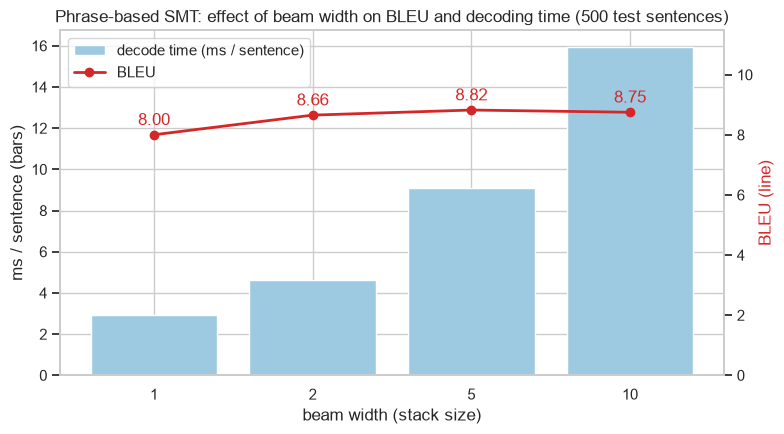

In [23]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
b = sweep.index.astype(str)
ax1.bar(b, sweep['ms / sentence (mean)'], color='#9ecae1', label='decode time (ms / sentence)')
ax1.set(xlabel='beam width (stack size)', ylabel='ms / sentence (bars)')
ax2 = ax1.twinx()
ax2.plot(b, sweep['BLEU (sacreBLEU, lowercased, detok)'], color='#d62728', marker='o', lw=2, label='BLEU')
for x, y in zip(b, sweep['BLEU (sacreBLEU, lowercased, detok)']):
    ax2.annotate(f'{y:.2f}', (x, y), textcoords='offset points', xytext=(0, 7), ha='center', color='#d62728')
ax2.set_ylabel('BLEU (line)', color='#d62728'); ax2.grid(False)
ax2.set_ylim(0, sweep['BLEU (sacreBLEU, lowercased, detok)'].max() * 1.3)
ax1.set_title('Phrase-based SMT: effect of beam width on BLEU and decoding time (500 test sentences)')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout(); plt.savefig(FIG / 'C_beam_sweep.png', dpi=120); plt.show()

### C.8 Final system outputs (written for Part D)
The deployed beam width is the **smallest beam whose BLEU is within 0.1 of the best beam**: past that point a
wider beam only adds latency. Outputs are detokenized with `MosesDetokenizer(lang='de')`, one line per input.

In [24]:
best_bleu = sweep['BLEU (sacreBLEU, lowercased, detok)'].max()
BEAM = int(min(bm for bm in sweep.index if sweep.loc[bm, 'BLEU (sacreBLEU, lowercased, detok)'] >= best_bleu - 0.1))
print(f'chosen beam width: {BEAM}')

eval_src = [preprocess(s, 'en') for s in eval_set.en]
stress_src = [preprocess(s, 'en') for s in stress_set.en]
smt_tok = {'test': sweep_out[BEAM],
           'eval': [decoder.translate(s, beam=BEAM) for s in eval_src],
           'stress': [decoder.translate(s, beam=BEAM) for s in stress_src]}
smt_detok = {k: [detok(h) for h in v] for k, v in smt_tok.items()}

def write_lines(path, lines):
    assert all('\n' not in l for l in lines)
    path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

for name, n in [('test', len(test_en)), ('eval', len(eval_set)), ('stress', len(stress_set))]:
    assert len(smt_detok[name]) == n
    write_lines(OUT / f'smt_{name}.de', smt_detok[name])
(OUT / 'smt_timing.json').write_text(json.dumps({'beam_width': BEAM,
                                                  'seconds_per_sentence': [round(x, 6) for x in sweep_times[BEAM]]}))
for f in ['smt_test.de', 'smt_eval.de', 'smt_stress.de', 'smt_timing.json']:
    p = OUT / f
    print(f'{f:16s} {p.stat().st_size:>7,} bytes', f'{len(p.read_text(encoding="utf-8").splitlines())} lines' if f.endswith('.de') else '')
print(f'mean SMT latency at beam {BEAM}: {1000 * np.mean(sweep_times[BEAM]):.1f} ms / sentence')

chosen beam width: 5
smt_test.de       60,066 bytes 500 lines
smt_eval.de        1,474 bytes 15 lines
smt_stress.de        572 bytes 8 lines
smt_timing.json    4,999 bytes 
mean SMT latency at beam 5: 9.1 ms / sentence


In [25]:
# Fill the SMT column of the shared human-rating and stress-tagging sheets (scores and tags are left for humans).
ratings_path, tags_path = OUT / 'ratings.csv', OUT / 'stress_error_tags.csv'
ratings = pd.read_csv(ratings_path, dtype={'smt': 'object'})
smt_by_id = {f'T{i:03d}': h for i, h in enumerate(smt_detok['test'])} | dict(zip(eval_set.id, smt_detok['eval']))
ratings['smt'] = ratings['id'].map(smt_by_id)
assert ratings['smt'].notna().all()
ratings.to_csv(ratings_path, index=False, encoding='utf-8')
tags = pd.read_csv(tags_path, dtype={'smt': 'object'})
tags['smt'] = tags['id'].map(dict(zip(stress_set.id, smt_detok['stress'])))
tags.to_csv(tags_path, index=False, encoding='utf-8')
print(f'filled smt column: {ratings_path.name} ({len(ratings)} rows), {tags_path.name} ({len(tags)} rows)')

filled smt column: ratings.csv (40 rows), stress_error_tags.csv (8 rows)


### C.9 Example translations (source, reference, SMT output)

In [26]:
src_vocab = {w for s in train_en for w in s}
oov = lambda toks: [w for w in toks if w not in src_vocab]
EXAMPLES = list(range(0, 500, 50))                     # 10 test sentences, evenly spaced, not cherry-picked
ex = pd.DataFrame({'id': [f'T{i:03d}' for i in EXAMPLES],
                   'source (EN)': [test_raw_en[i] for i in EXAMPLES],
                   'reference (DE)': [test_raw_de[i] for i in EXAMPLES],
                   f'SMT (beam {BEAM})': [smt_detok['test'][i] for i in EXAMPLES],
                   'OOV passed through': [', '.join(oov(test_en[i])) for i in EXAMPLES],
                   'sentence BLEU': [round(sacrebleu.sentence_bleu(smt_detok['test'][i], [test_raw_de[i]],
                                                                   lowercase=True).score, 1) for i in EXAMPLES]})
ex

,id,source (EN),reference (DE),SMT (beam 5),OOV passed through,sentence BLEU
0,T000,The dollar and the pound then shared international primacy in the 1920’s and 1930’s.,In den 1920er und 1930er Jahren dann teilten sich der Dollar und das Pfund die internationale Vorrangstellung.,die dollar und pfund dann gemeinsamen internationale primacy in die 1920 und die 1930er jahre.,1920,6.5
1,T050,"In the second half of the century, farsighted leaders looked beyond revenge and gradually constructed the institutio...",In der zweiten Hälfte des Jahrhunderts sahen weit blickende Führer über die Rache hinaus und errichteten allmählich ...,in der zweiten die hälfte der jahrhundert farsighted führer geschaut hinaus revenge und allmählich ab und entwickelt...,farsighted,13.9
2,T100,"The difficulty with such a suggestion is that it would imply a relative weakening of the national states, including ...","Die Schwierigkeit eines derartigen Vorschlags besteht darin, dass dies eine relative Schwächung der Nationalstaaten,...","der schwierigkeit, mit eine solche vorschlag ist, dass es wäre ein relatives schwächung des die nationale staaten, u...",,7.6
3,T150,"But this role has atrophied with the rising expectation that they should be “normal,” representing their populations...","Doch ist diese Rolle angesichts der zunehmenden Erwartung, dass sie möglichst „normal“ sein und die Gewohnheiten und...","aber diese rolle hat atrophied mit am rande erwartung sollte sie ""normalen"" representing ihre bevölkerungen der gewo...","atrophied, representing, tastes",4.6
4,T200,"Correspondingly, RMB liabilities owed by mainlanders and multinationals decreased, as did RMB assets held in Hong Kong.","Dementsprechend sanken die RMB-Verbindlichkeiten der Festländer und multinationalen Unternehmen, wie auch das RMB-Ka...","correspondingly, rmb verbindlichkeiten owed durch mainlanders und multinationals decreased, wie die dies taten rmb v...","correspondingly, rmb, mainlanders, multinationals, rmb",9.2
5,T250,There is some truth in this.,Darin liegt eine gewisse Wahrheit.,es besteht ein funken wahrheit in diesem.,,6.6
6,T300,"If they choose the latter option, the new state will come into being on July 9, 2011.","Falls sie sich für Letzteres entscheiden, entsteht am 9. Juli 2011 dieser neue Staat.","wenn sie die ein letztere option zurückreift, den neuen staat wird stelle werden juli 9, 2011.",,3.3
7,T350,That is a mistake.,Das ist ein Fehler.,das ist ein fehler.,,100.0
8,T400,How large and fast is the flow?,Wie stark und schnell ist die Strömung?,wie eines großen und den rasch ist die fließen?,,10.6
9,T450,A better approach to reducing unemployment would be a new and expanded round of quantitative easing.,"Ein besserer Ansatz zur Bekämpfung der Arbeitslosigkeit wäre eine neue, ausgeweitete Runde der quantitativen Lockerung.",eine bessere ansatzes hinsichtlich der arbeitslosigkeit zu reduzieren wäre einer neuen und man davon aus runde von d...,,15.0


In [27]:
ev = eval_set[['id', 'category', 'en', 'de_ref']].assign(smt=smt_detok['eval'],
                                                         oov=[', '.join(oov(s)) for s in eval_src])
st = stress_set[['id', 'phenomenon', 'en', 'de_ref']].assign(smt=smt_detok['stress'],
                                                              oov=[', '.join(oov(s)) for s in stress_src])
display(ev); display(st)

,id,category,en,de_ref,smt,oov
0,E01,short,Stock markets are rallying.,Die Aktienmärkte steigen.,die börsen sind rallying.,
1,E02,short,This can be done in creative ways.,Das kann auf kreative Weise erfolgen.,dies kann man tun in kreativ zu verbessern.,
2,E03,short,Immanuel Kant described two types of politicians.,Immanuel Kant beschrieb zwei Arten von Politikern.,immanuel kant beschrieben zwei arten von politiker.,"immanuel, kant"
3,E04,long,A recent study by Andy Haldane and others at the Bank of England casts doubt on the prospect of a return to the stat...,"Eine jüngere Studie von Andy Haldane und anderen von der Bank of England lässt Zweifel aufkommen, was die Aussicht a...","eine kürzlich studie durch andy haldane und andere bei der bank von england, versuchte casts zweifel an aussicht ste...","andy, haldane, ante"
4,E05,long,We count on China’s continued support for European and American efforts in making sure that Iran’s nuclear program r...,"Wir setzen auf Chinas dauerhafte Unterstützung der europäischen und amerikanischen Bemühungen, dafür zu sorgen, dass...","wir mehr auf chinas fortgesetzte unterstützung für die europäischen und amerikanischen bemühungen machen sicher, das...",
5,E06,long,At the top of the agenda should be ratification of improvements to a crucial nuclear security instrument – theConven...,Ganz oben auf der Tagesordnung sollte die Verabschiedung von Verbesserungen eines entscheidenden Instruments zur nuk...,der spitze die agenda sollte sich die ratifizierung des verbesserungen zu eine entscheidende die nukleare sicherheit...,theconvention
6,E07,ne_numbers,"The 10 new EU members do not have the same history as the Netherlands, Belgium, and Luxembourg.","Die 10 neuen EU-Mitglieder haben eine andere Geschichte als die Niederlande, Belgien und Luxemburg.","die 10 neue eu-mitgliedstaaten nicht haben das gleiche geschichte, als der niederlande - schlagen sich deutschland u...",luxembourg
7,E08,ne_numbers,Putinism claimed victory after invading tiny Georgia in 2008.,"Putin verbuchte den Sieg für sich, nachdem er 2008 Truppen in das winzige Georgien einmarschieren ließ.",putinismus sieg verkündeten nach invading winzige georgien in 2008.,
8,E09,ne_numbers,One such rule is the Maastricht Treaty’s cap on member states’ public debt at 60% of GDP.,"Eine dieser Regeln ist die Grenze von 60% des BIP, die im Maastricht-Vertrag für die Staatsschulden der Mitgliedstaa...",eine solche herrschaft ist die vertrag von maastricht grenzen der cap auf der mitglieder öffentlichen schulden 60% d...,
9,E10,domain_term,The spokesperson declined to comment on the allegations at a press conference.,"Der Sprecher lehnte es auf einer Pressekonferenz ab, sich zu den Vorwürfen zu äußern.","die spokesperson damals ab, auf die zu comment allegations zu einem presse konferenz.",allegations


,id,phenomenon,en,de_ref,smt,oov
0,S01,negation,Police say the suspect was not armed and did not resist arrest.,"Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.",die polizei sagen vermute war nicht bewaffneten und nicht widerstehen verhaftung.,
1,S02,word_order,The chancellor said that the government would announce new sanctions against Russia on Monday.,"Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.","die schatzkanzler behauptete, die regierung würde diesen announce neue sanktionspolitik gegen russland auf monday.",
2,S03,idiom_mwe,Opposition leaders say the reform has been kicked into the long grass.,"Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.",opposition führer sagen reformen wurde kicked in die lange grass.,grass
3,S04,oov_compound,Federal Constitutional Court halts speed-limit law,Bundesverfassungsgericht stoppt Tempolimit-Gesetz,auch wenn verfassungsmäßige föderalen gericht halts speed-limit gesetz,"halts, speed-limit"
4,S05,ambiguity,Union leaders call strike at Frankfurt airport,Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf,union führer nennen ändernden auf frankfurt airport,
5,S06,quotation_negation,"""We will not give in,"" Scholz told reporters in Berlin on 3 October.","„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.","""wir wird nicht an sich gerissen in,"" scholz gesagt den in berlin auf 3 oktober.",scholz
6,S07,headline_dropped_verb,Storm leaves thousands without power in Bavaria,Sturm lässt Tausende in Bayern ohne Strom,sturm starkes tausende ohne macht in bavaria,bavaria
7,S08,oov_neologism,Deepfake video of mayor sparks outrage,Deepfake-Video des Bürgermeisters sorgt für Empörung,der bürgermeister von video deepfake sparks outrage,"deepfake, sparks, outrage"


In [28]:
# How the beam changes the output: sentences whose translation differs between beam 1 and the chosen beam.
diff = [i for i in range(len(test_en)) if sweep_out[1][i] != sweep_out[BEAM][i]]
print(f'{len(diff)} / {len(test_en)} test outputs change between beam 1 and beam {BEAM}')
pd.DataFrame({'source': [' '.join(test_en[i]) for i in diff[:4]],
              'beam 1': [' '.join(sweep_out[1][i]) for i in diff[:4]],
              f'beam {BEAM}': [' '.join(sweep_out[BEAM][i]) for i in diff[:4]],
              'reference': [' '.join(test_de[i]) for i in diff[:4]]})

418 / 500 test outputs change between beam 1 and beam 5


,source,beam 1,beam 5,reference
0,the dollar and the pound then shared international primacy in the 1920 's and 1930 's .,die dollar und pfund dann aufgeteilt internationale primacy in den 1920 und die ersten 1930er jahre .,die dollar und pfund dann gemeinsamen internationale primacy in die 1920 und die 1930er jahre .,in den 1920er und 1930er jahren dann teilten sich der dollar und das pfund die internationale vorrangstellung .
1,"the 10 new eu members do not have the same history as the netherlands , belgium , and luxembourg .","die neue eu-mitgliedstaaten 10 nicht haben das gleiche geschichte als den niederlanden geben , und luxembourg deutsc...","die 10 neue eu-mitgliedstaaten nicht haben das gleiche geschichte , als der niederlande - schlagen sich deutschland ...","die 10 neuen eu-mitglieder haben eine andere geschichte als die niederlande , belgien und luxemburg ."
2,a recent study by andy haldane and others at the bank of england casts doubt on the prospect of a return to the stat...,"eine kürzlich studie durch andy haldane und andere bei der bank von england , casts zweifel an aussichten eine rückk...","eine kürzlich studie durch andy haldane und andere bei der bank von england , versuchte casts zweifel an aussicht st...","eine jüngere studie von andy haldane und anderen von der bank of england lässt zweifel aufkommen , was die aussicht ..."
3,let us hope it is a full and fair examination based on the report 's findings and recommendations .,wir wollen hoffen sie ist eine vollständige und faire examination auf der grundlage von der bericht des ergebnisse u...,"wir wollen hoffen sie ist eine vollständige und faire examination , die auf der bericht des ergebnisse und empfehlun...",hoffen wir auf eine umfassende und faire debatte auf grundlage der ergebnisse und empfehlungen des berichts .


In [29]:
# OOV pass-through statistics on the test set
n_oov = sum(len(oov(s)) for s in test_en); n_tok = sum(map(len, test_en))
copied = sum(w in h for s, h in zip(test_en, sweep_out[BEAM]) for w in oov(s))
has_oov = np.array([bool(oov(s)) for s in test_en])
hyp_d, ref_d = np.array(smt_detok['test'], dtype=object), np.array(test_raw_de, dtype=object)
print(f'test OOV tokens: {n_oov} / {n_tok} ({100 * n_oov / n_tok:.1f}%), all passed through unchanged: {copied == n_oov}')
print(f'BLEU on sentences with OOV: {sacre_bleu(list(hyp_d[has_oov]), list(ref_d[has_oov])):.2f} '
      f'({has_oov.sum()} sents) vs OOV-free: {sacre_bleu(list(hyp_d[~has_oov]), list(ref_d[~has_oov])):.2f} ({(~has_oov).sum()} sents)')

test OOV tokens: 358 / 9116 (3.9%), all passed through unchanged: True
BLEU on sentences with OOV: 7.63 (233 sents) vs OOV-free: 10.01 (267 sents)


### C.10 Observations

* **Pipeline size.** grow-diag-final aligns ~16 points per sentence and leaves ~23% of tokens unaligned
  (intersection leaves ~50%, union <1%). Extraction yields **529,053 phrase-pair tokens / 412,345 unique phrase
  pairs** over 143,044 English phrases. Intersection's sparse alignment produces 2.6× more, mostly loose pairs
  (unaligned words attach freely), while union's dense noisy links block all but 22k pairs. This illustrates
  the precision/recall trade-off behind our choice.
* **Language model.** The KN trigram reaches a held-out perplexity of **≈482** (7.3% OOV tokens), against ≈493 for
  a KN bigram and >7,000 for add-k. Interpolated KN matters far more than the n-gram order at this data size.
* **Tuning.** On the 300-pair dev slice, the best setting was λ_LM = 0.5, word penalty +0.5 and distortion
  0.5 (dev BLEU ≈10.0, length ratio ≈1.0). It sits on the edge of the grid for λ_LM, so a finer grid (or MERT)
  could gain a little more. A low LM weight is plausible: the LM is trained on only 180k tokens and is
  over-confident about frequent n-grams such as *die …*.
* **Beam width.** BLEU rises from **8.0 (beam 1) to 8.7 (beam 2) and 8.8 (beam 5)**, then levels off (8.75 at
  beam 10), while decoding time grows roughly linearly with the beam (≈3 → 9 → 15 ms per sentence). Beam 1 is a
  greedy decoder that commits to the locally best phrase and cannot undo a bad early reordering. Beyond beam 5
  the search finds hypotheses with a *higher model score* that are no better translations: the errors left are
  **model errors** (phrase table, LM), not **search errors**. We deploy **beam 5**: about 9 ms per sentence in pure
  Python, still far faster than the NMT model on CPU (Part D).
* **Absolute quality.** **8.8 BLEU** (case-insensitive sacreBLEU) is in the expected 3–12 range for 10k training
  pairs. The output is often understandable word by word and gets short, frequent constructions right
  (*that is a mistake. → das ist ein fehler.*; *immanuel kant beschrieben zwei arten von politiker*). Typical errors
  in the examples:
  * **Agreement and case**, because the trigram LM cannot enforce them over phrase boundaries
    (*die dollar*, *ein relatives schwächung des die nationale staaten*).
  * **No verb-final / verb-second reordering.** The distortion model is a linear penalty, so English SVO order
    leaks through (*… würde diesen announce neue sanktionspolitik …* in S02, *die herrschende koalition ihre
    mehrheit im parlament* with the participle *verloren* dropped in E11). German clause structure is beyond a
    phrase-local, distance-penalised reordering model, which is the IBM Model 1 distortion limitation again,
    one level up.
  * **Dropped words**, especially verbs: the decoder can cover a source word with a phrase whose German side
    omits it (E11 *lost*, S06 *reporters*).
  * **Noisy phrase pairs from garbage-collector alignments**. Examples: *the central bank raised → die
    zentralbank aufgewachsen sind* (*raised* as in "brought up"); *curb* → *einwanderung*.
* **OOV.** 3.9% of test tokens are unseen in training. They are **passed through unchanged** (all 358 copied), which
  is correct for names (*andy haldane*, *rmb*) but leaves English words in the output (*primacy, farsighted,
  casts, rallying*). BLEU drops from **10.0 on OOV-free sentences to 7.6** on the 233 sentences with an OOV.
* **Stress set (domain focus).** SMT fails in the ways the corpus statistics predict:
  * *Federal Constitutional Court* comes out word by word (*verfassungsmäßige föderalen gericht*), because the
    compound *Bundesverfassungsgericht* is not in the training data.
  * Headline verbs are OOV or mistranslated (*halts*, *sparks outrage*), and *power → macht* is the wrong sense.
  * *Union leaders → union führer*, and the place names *Bavaria* / *airport* stay English.
  * The idiom is translated literally (*kicked in die lange grass*).
  * Negation is kept (*nicht bewaffneten und nicht widerstehen*), but the reported-speech subjunctive is lost.

  These outputs are filled into `outputs/stress_error_tags.csv` for the joint error tagging in Part E.

## Part E — BLEU implemented from scratch
Following Papineni et al. (2002):
* **Clipped (modified) n-gram precision**: $p_n = \dfrac{\sum \min(\text{count}_{hyp}(g), \text{count}_{ref}(g))}{\sum \text{count}_{hyp}(g)}$ for $n = 1..4$.
* **Geometric mean** of $p_1..p_4$ with uniform weights.
* **Brevity penalty**: $BP = 1$ if $c > r$, otherwise $e^{1 - r/c}$ ($c$ = hypothesis length, $r$ = reference length).
* **Corpus BLEU** sums clipped matches, n-gram totals and lengths over all sentences *before* dividing, so it is
  not the mean of sentence scores.
* **Sentence BLEU smoothing**: a single sentence often has no 4-gram match, which makes the geometric mean 0.
  We use **add-1 smoothing for n ≥ 2** (Lin & Och 2004; "method 2" in Chen & Cherry 2014): 1 is added to both
  the clipped match count and the total count of every n-gram order from 2 to 4. Unigram precision is left
  unsmoothed, so a hypothesis with no word in common with the reference still scores 0.

In [30]:
def ngram_counts(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def bleu_stats(hyp, ref, max_n=4):
    """Sufficient statistics of one sentence: clipped matches[n], totals[n], hyp length, ref length."""
    matches, totals = [], []
    for n in range(1, max_n + 1):
        h, r = ngram_counts(hyp, n), ngram_counts(ref, n)
        matches.append(sum(min(c, r[g]) for g, c in h.items()))
        totals.append(max(len(hyp) - n + 1, 0))
    return matches, totals, len(hyp), len(ref)

def bleu_from_stats(matches, totals, c, r, smooth=False):
    if c == 0 or matches[0] == 0:
        return 0.0
    log_p = 0.0
    for n, (m, t) in enumerate(zip(matches, totals), start=1):
        if smooth and n > 1:
            m, t = m + 1, t + 1                       # add-1 smoothing for n >= 2
        if m == 0:
            return 0.0
        log_p += math.log(m / t)
    bp = 1.0 if c > r else math.exp(1 - r / c)
    return 100 * bp * math.exp(log_p / len(matches))

def sentence_bleu(hyp_tokens, ref_tokens, smooth=True):
    return bleu_from_stats(*bleu_stats(hyp_tokens, ref_tokens), smooth=smooth)

def corpus_bleu(list_hyp, list_ref):
    M, T, c, r = [0] * 4, [0] * 4, 0, 0
    for h, ref in zip(list_hyp, list_ref):
        m, t, hl, rl = bleu_stats(h, ref)
        M = [a + b for a, b in zip(M, m)]; T = [a + b for a, b in zip(T, t)]; c += hl; r += rl
    return bleu_from_stats(M, T, c, r, smooth=False)

# Worked example
hyp = 'die regierung hat die neuen sanktionen angekündigt .'.split()
ref = 'die regierung kündigte neue sanktionen an .'.split()
m, t, c, r = bleu_stats(hyp, ref)
print('clipped matches', m, 'totals', t, f'c={c} r={r}', f'sentence BLEU (add-1) = {sentence_bleu(hyp, ref):.2f}',
      f'| unsmoothed = {sentence_bleu(hyp, ref, smooth=False):.2f}')

clipped matches [4, 1, 0, 0] totals [8, 7, 6, 5] c=8 r=7 sentence BLEU (add-1) = 23.36 | unsmoothed = 0.00


### E.1 Validation against sacreBLEU and NLTK
All systems are scored on the **same pre-tokenized, lowercased token sequences**, using
`sacrebleu.corpus_bleu(..., tokenize='none')` so that sacreBLEU does not re-tokenize. NMT output (from
Member 1) is tokenized with the shared `preprocess()`. At sentence level we compare against sacreBLEU's
`add-k` smoothing with k = 1, which is the same method.

In [31]:
from nltk.translate.bleu_score import corpus_bleu as nltk_corpus_bleu

ref_tok = test_de
systems = {f'SMT beam {bm}': sweep_out[bm] for bm in C['BEAMS']}
nmt_path = OUT / 'nmt_test.de'
if nmt_path.exists():
    systems['NMT (opus-mt-en-de)'] = [preprocess(s, 'de') for s in nmt_path.read_text(encoding='utf-8').splitlines()]

rows = []
for name, hyps in systems.items():
    ours = corpus_bleu(hyps, ref_tok)
    sacre = sacrebleu.corpus_bleu([' '.join(h) for h in hyps], [[' '.join(r) for r in ref_tok]], tokenize='none').score
    nltk_ = 100 * nltk_corpus_bleu([[r] for r in ref_tok], hyps)
    rows.append({'system': name, 'ours': ours, 'sacreBLEU (tokenize=none)': sacre, 'NLTK corpus_bleu': nltk_,
                 '|ours - sacreBLEU|': abs(ours - sacre), '|ours - NLTK|': abs(ours - nltk_)})
validation = pd.DataFrame(rows).set_index('system')
assert (validation['|ours - sacreBLEU|'] < 0.1).all()
validation.round(4)

,ours,sacreBLEU (tokenize=none),NLTK corpus_bleu,|ours - sacreBLEU|,|ours - NLTK|
system,,,,,
SMT beam 1,8.2355,8.2355,8.2350,0.0,0.0005
SMT beam 2,8.8460,8.8460,8.8455,0.0,0.0006
SMT beam 5,9.0350,9.0350,9.0347,0.0,0.0003
SMT beam 10,9.0024,9.0024,9.0021,0.0,0.0003
NMT (opus-mt-en-de),28.7005,28.7005,28.6957,0.0,0.0048


515 sentences: max |ours - sacreBLEU add-k(1)| = 4.26e-14, mean sentence BLEU ours 15.948 vs sacreBLEU 15.948


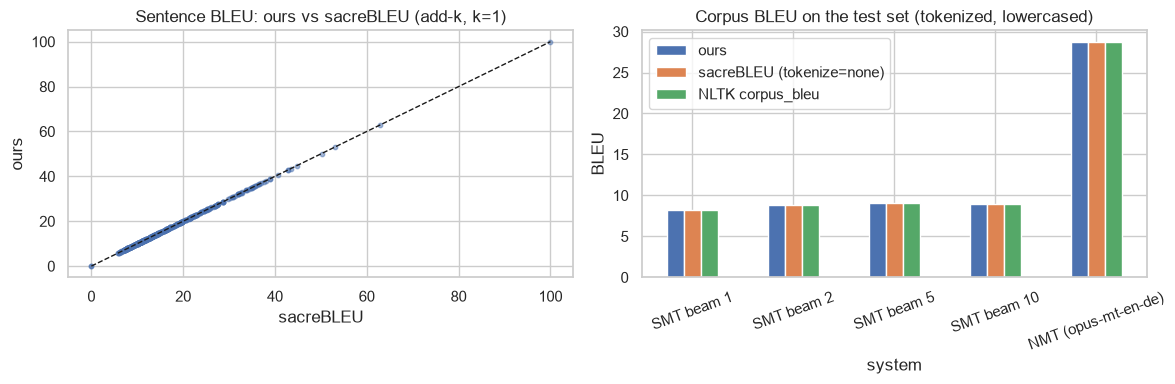

In [32]:
# Sentence-level validation on all 500 SMT test sentences and on the eval set.
pairs_ = list(zip(sweep_out[BEAM], ref_tok)) + list(zip(smt_tok['eval'], [preprocess(s, 'de') for s in eval_set.de_ref]))
ours_s = np.array([sentence_bleu(h, r) for h, r in pairs_])
sacre_s = np.array([sacrebleu.sentence_bleu(' '.join(h), [' '.join(r)], tokenize='none', smooth_method='add-k',
                                            smooth_value=1, use_effective_order=False).score for h, r in pairs_])
print(f'{len(pairs_)} sentences: max |ours - sacreBLEU add-k(1)| = {np.abs(ours_s - sacre_s).max():.2e}, '
      f'mean sentence BLEU ours {ours_s.mean():.3f} vs sacreBLEU {sacre_s.mean():.3f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(sacre_s, ours_s, s=10, alpha=.5); ax[0].plot([0, 100], [0, 100], 'k--', lw=1)
ax[0].set(title='Sentence BLEU: ours vs sacreBLEU (add-k, k=1)', xlabel='sacreBLEU', ylabel='ours')
validation[['ours', 'sacreBLEU (tokenize=none)', 'NLTK corpus_bleu']].plot.bar(ax=ax[1], rot=20)
ax[1].set(title='Corpus BLEU on the test set (tokenized, lowercased)', ylabel='BLEU')
plt.tight_layout(); plt.savefig(FIG / 'E_bleu_validation.png', dpi=120); plt.show()

**Validation result.** Our corpus BLEU matches sacreBLEU (`tokenize='none'`) to floating-point precision for
every SMT beam width and for the NMT system. It also matches NLTK's `corpus_bleu` to within 0.005, a tiny
difference that comes from NLTK's internal handling of the brevity penalty and its use of fractions. Our add-1 smoothed sentence BLEU
matches sacreBLEU's `add-k` (k = 1) on every sentence. The from-scratch implementation is therefore correct, and
it reproduces both reference implementations exactly when the tokenization is controlled.

**Which BLEU we report where.** BLEU depends on tokenization (Post 2018), so all numbers *compared across
systems* (the Part D table) use sacreBLEU with its standard 13a tokenizer and `lowercase=True` on detokenized
output. SMT output is lowercased, so cased BLEU would penalise it for something the system was never trained to
do. The tokenized BLEU above (`tokenize='none'` on our Moses tokens) is about 0.1–0.2 points higher, because the
two tokenizers split differently (e.g. compounds with hyphens).